# **Laporan Praktikum: Sistem Akuisisi & Pengelolaan Data**
### *Studi Komparatif Lintas Sektoral & Pemetaan Pariwisata Pulau Lombok*

---

### **I. Identitas Peneliti**

| Atribut | Keterangan |
| :--- | :--- |
| **Nama Lengkap** | Ni Kadek Rahayu Windari |
| **NIM** | `2501010176` |
| **Program Studi** | Informatika (Kelas F) |
| **Institusi** | Institut Bisnis dan Teknologi Indonesia (INSTIKI) |
| **Dosen Pengampu** | Dr. I Gede Totok Suryawan, S.Kom., M.T. |

---

### **II. Ruang Lingkup & Metodologi**

Kajian komprehensif ini mengintegrasikan data industri pariwisata lokal, fluktuasi iklim mikro harian, dan struktur administratif kecamatan di **5 kabupaten/kota utama Pulau Lombok** (*Lombok Barat, Lombok Tengah, Lombok Timur, Lombok Utara, dan Kota Mataram*), dengan menetapkan **Kabupaten Lombok Barat** sebagai unit analisis spasial mendalam.

Untuk membangun fondasi analisis yang kuat, akuisisi data dilakukan secara transparan melalui tiga instrumen utama:

| No | Metode Pengumpulan | Sumber Data & Cakupan | Kriteria Validasi | Status |
| :---: | :--- | :--- | :---: | :---: |
| **1** | **Open Data Download** | Portal Resmi Satu Data NTB (*Volume Usaha Pariwisata*) | &ge; 100 Baris | **Terpenuhi** |
| **2** | **Integrasi REST API** | Open-Meteo Historical Archive (*Parameter Cuaca Historis*) | &ge; 30 Baris | **Terpenuhi** |
| **3** | **Web Scraping** | Wikipedia Indonesia & Inggris (*Struktur Administratif Kecamatan*) | Kepatuhan `robots.txt` | **Terpenuhi** |

> **Kunci Integrasi Relasional:** Konsolidasi seluruh sumber data dilakukan secara otomatis melalui atribut relasional **`kunci_wilayah`** (normalisasi nama daerah) dan **`tahun_kunci`** menggunakan metode penggabungan `validate="many_to_one"` untuk menjamin integritas data bebas dari anomali duplikasi.

---

### **III. Petunjuk Eksekusi Sistem**
1. Eksekusi seluruh sel secara berurutan dari atas ke bawah (**Runtime > Run all**) untuk memastikan seluruh variabel, fungsi utilitas, dan direktori penyimpanan terkonfigurasi dengan benar di dalam memori.
2. Alur program ini dirancang secara modular dan dilengkapi penanganan kesalahan adaptif (*fault-tolerant request*) guna mengantisipasi kendala jaringan atau pembatasan server saat proses penarikan data.

##  1 Setup Lingkungan & Fungsi Utilitas
Tahap ini menginstal dan memuat pustaka yang dibutuhkan (`requests`, `pandas`, `BeautifulSoup`, `matplotlib`), mengatur identitas `User-Agent` menggunakan email kampus pribadi (`2501010176@instiki.ac.id`), menyiapkan direktori proyek (`data/raw`, `data/processed`, `docs`), serta mendefinisikan fungsi utilitas untuk *HTTP retry*, penyimpanan *raw bytes*, penghitungan *hash* MD5, normalisasi wilayah, dan pemeriksaan `robots.txt`.

In [95]:
# ==============================================================================
# SEL 1: INISIALISASI LINGKUNGAN, KONFIGURASI IDENTITAS, DAN FUNGSI UTILITAS
# ==============================================================================

# --- 1. Verifikasi & Instalasi Dependensi Wajib ---
import importlib
import subprocess
import sys

PAKET_WAJIB = [
    ("beautifulsoup4", "bs4"),
    ("lxml", "lxml"),
    ("matplotlib", "matplotlib"),
    ("requests", "requests"),
    ("pandas", "pandas"),
]

for paket, modul in PAKET_WAJIB:
    try:
        importlib.import_module(modul)
    except ImportError:
        print(f"[Setup] Menginstal paket {paket}...")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", paket], check=False)

# --- 2. Impor Libraries Standar (Python Standard Library) ---
import csv
import hashlib
import io
import json
import os
import re
import time
from datetime import date, datetime, timedelta
from pathlib import Path
from urllib.parse import unquote, urlparse
from urllib.robotparser import RobotFileParser

# --- 3. Impor Libraries Pihak Ketiga (Third-Party Libraries) ---
import pandas as pd
import requests
from bs4 import BeautifulSoup

# --- 4. Konfigurasi HTML Parser & Engine Tampilan ---
try:
    import lxml  # noqa: F401
    PARSER_HTML = "lxml"
except ImportError:
    PARSER_HTML = "html.parser"

try:
    display
except NameError:
    display = print

# ==============================================================================
# KONFIGURASI IDENTITAS MAHASISWA & PARAMETER TRANSAKSI HTTP
# ==============================================================================
NAMA = "Ni Kadek Rahayu Windari"
NIM = "2501010176"
EMAIL_KAMPUS = "2501010176@instiki.ac.id"

# Validasi awal kepatuhan aturan UTS akademis
assert "@" in EMAIL_KAMPUS and EMAIL_KAMPUS.lower().endswith("instiki.ac.id"), \
    "EMAIL_KAMPUS wajib menggunakan alamat email resmi mahasiswa @instiki.ac.id"
assert not EMAIL_KAMPUS.lower().startswith("mahasiswa@"), \
    "Gunakan email pribadi Anda, dilarang menggunakan email contoh dari modul."

# Parameter Header & Kebijakan Akses Jaringan Sopan
UA = f"INSTIKI-BIFP243-UTS/1.0 ({EMAIL_KAMPUS})"
HEADERS = {"User-Agent": UA, "Accept": "*/*"}
TIMEOUT = 15  # Batas waktu tunggu maksimal per request (detik)
JEDA = 1.5    # Jeda (delay) sopan antar-request ke server (detik)

# ==============================================================================
# MANAJEMEN STRUKTUR DIREKTORI PROYEK
# ==============================================================================
BASE = Path(f"uts_dam_{NIM}")
RAW = BASE / "data/raw"
PROC = BASE / "data/processed"
DOCS = BASE / "docs"

for folder in (RAW, PROC, DOCS):
    folder.mkdir(parents=True, exist_ok=True)

# Logger Global Transaksi & Variabel Wilayah
endpoint_log = []   # Menyimpan riwayat kode status respons HTTP
waktu_akses = {}    # Riwayat waktu penarikan berkas mentah (raw)
LOMBOK_KEYS = {"lombok barat", "lombok tengah", "lombok timur", "lombok utara", "mataram"}

# ==============================================================================
# DEFINISI FUNGSI UTILITAS (PROVENANCE & DATA ACQUISITION)
# ==============================================================================

def ambil_dengan_retry(url, params=None, maks_percobaan=4, jeda_awal=2.0):
    """Mengambil dokumen via GET dengan penanganan fault-tolerance, retry, dan backoff."""
    jeda = jeda_awal
    for percobaan in range(1, maks_percobaan + 1):
        time.sleep(JEDA)
        try:
            resp = requests.get(url, params=params, headers=HEADERS, timeout=TIMEOUT)
            endpoint_log.append({
                "waktu": datetime.now().isoformat(timespec="seconds"),
                "url_final": resp.url,
                "status": resp.status_code,
                "detik": round(resp.elapsed.total_seconds(), 2),
                "percobaan": percobaan
            })
            if resp.status_code == 200:
                return resp

            if resp.status_code == 429:
                try:
                    tunggu = float(resp.headers.get("Retry-After", jeda))
                except ValueError:
                    tunggu = jeda
                print(f"  [Percobaan {percobaan}] Terkena Rate Limit (HTTP 429). Menunggu {tunggu}s...")
                time.sleep(tunggu)
            elif 500 <= resp.status_code < 600:
                print(f"  [Percobaan {percobaan}] Kesalahan Server (HTTP {resp.status_code}). Menunggu {jeda}s...")
                time.sleep(jeda)
            else:
                raise RuntimeError(f"HTTP Error {resp.status_code}: {resp.reason} -> {resp.url}")
        except (requests.Timeout, requests.ConnectionError) as err:
            print(f"  [Percobaan {percobaan}] Kendala Jaringan ({type(err).__name__}). Menunggu {jeda}s...")
            time.sleep(jeda)
        jeda *= 2
    raise RuntimeError(f"Gagal memuat URL setelah {maks_percobaan} percobaan: {url}")


def simpan_raw(path, isi_bytes):
    """Menulis file mentah (raw bytes) secara aman ke media penyimpanan lokal."""
    target = Path(path)
    target.write_bytes(isi_bytes)
    waktu_akses[target.name] = datetime.now().isoformat(timespec="seconds")


def hitung_md5(path):
    """Menghasilkan nilai checksum MD5 untuk menjaga integritas dan ketertelusuran data."""
    hasher = hashlib.md5()
    with open(path, "rb") as berkas:
        for potongan in iter(lambda: berkas.read(8192), b""):
            hasher.update(potongan)
    return hasher.hexdigest()


def norm_wilayah(teks):
    """Standarisasi penulisan nama wilayah untuk mempermudah relasi antar-tabel."""
    s = str(teks).lower()
    s = re.sub(r"\b(kabupaten|kab|kota|regency|city)\b\.?", " ", s)
    s = re.sub(r"[^a-z0-9 ]", " ", s)
    return re.sub(r"\s+", " ", s).strip()


def ekstrak_tahun(seri):
    """Mengekstrak deretan angka tahun 4-digit secara aman dari tipe data teks."""
    return pd.to_numeric(seri.astype(str).str.extract(r"((?:19|20)\d{2})")[0], errors="coerce")


def cek_kepatuhan(url, nama_berkas_robots, user_agent=UA):
    """Melakukan audit kebijakan robots.txt dari domain target sebelum aktivitas penambangan."""
    parsed = urlparse(url)
    robots_url = f"{parsed.scheme}://{parsed.netloc}/robots.txt"
    try:
        resp = ambil_dengan_retry(robots_url)
        isi, status = resp.text, resp.status_code
        simpan_raw(RAW / nama_berkas_robots, resp.content)
    except RuntimeError as err:
        if "404" in str(err):
            isi, status = "", 404
        else:
            raise

    rp = RobotFileParser()
    rp.parse(isi.splitlines())
    return {
        "url": url,
        "robots_url": robots_url,
        "status_robots": status,
        "boleh_diakses": True if status == 404 else rp.can_fetch(user_agent, url),
        "crawl_delay": rp.crawl_delay(user_agent),
        "cuplikan_robots_txt": isi[:300],
        "waktu_cek": datetime.now().isoformat(timespec="seconds"),
    }

# --- 5. Tampilkan Status Sukses Inisialisasi ---
print("=" * 78)
print(f"LINGKUNGAN UTS SELESAI DIKONFIGURASI | {NAMA} ({NIM})")
print(f"  Lokasi Root Proyek : {BASE.resolve()}")
print(f"  Konfigurasi Jaringan: Timeout={TIMEOUT}s | Jeda Sopan={JEDA}s | Parser={PARSER_HTML}")
print("=" * 78)

LINGKUNGAN UTS SELESAI DIKONFIGURASI | Ni Kadek Rahayu Windari (2501010176)
  Lokasi Root Proyek : /content/uts_dam_2501010176
  Konfigurasi Jaringan: Timeout=15s | Jeda Sopan=1.5s | Parser=lxml


## Sel 2: Konfigurasi dan Akuisisi Dataset CSV (Portal Satu Data NTB)

### Informasi Katalog Dataset
* **Nama Dataset:** Jumlah Usaha Industri Pariwisata berdasarkan Jenis Usaha dan Kabupaten/Kota Provinsi NTB
* **Penerbit Data:** Dinas Pariwisata Provinsi Nusa Tenggara Barat
* **Tingkat Agregasi:** Tingkat Kabupaten dan Kota
* **Rentang Waktu:** Periode Tahunan (2022 s.d. 2024)

Sel kode di bawah ini mengatur metadata sumber katalog, mengunduh berkas CSV secara otomatis dari portal **Satu Data NTB** (dengan mekanisme unggah manual sebagai cadangan apabila portal membatasi unduhan langsung), menyimpan berkas mentah apa adanya ke direktori `data/raw/`, serta memverifikasi kesiapan berkas sebelum tahap pembacaan dan identifikasi data.

In [96]:
# ==============================================================================
# SEL 2: KONFIGURASI KATALOG & AKUISISI DATASET CSV (SATU DATA NTB)
# ==============================================================================
import re
from datetime import date, datetime
from pathlib import Path
from urllib.parse import unquote, urlparse

import pandas as pd
import requests

# ==============================================================================
# 1. PERSIAPAN DIREKTORI & PEMBERSIHAN BERKAS NON-CSV
# ==============================================================================
RAW = Path("uts_dam_2501010176/data/raw")
RAW.mkdir(parents=True, exist_ok=True)

for salah_file in RAW.glob("*.ipynb"):
    salah_file.unlink()

# ==============================================================================
# 2. KONFIGURASI METADATA KATALOG & VARIABEL INISIAL
# ==============================================================================
CSV_PORTAL            = "Satu Data NTB (data.ntbprov.go.id), Dinas Pariwisata Provinsi NTB"
CSV_URL_SUMBER        = "https://data.ntbprov.go.id/dataset/9f040bf6-9148-42d7-9420-125ee229d599/show"
CSV_LISENSI           = "License Not Specified"
CSV_SATUAN            = "usaha (jumlah usaha industri pariwisata per jenis usaha); data tahunan periode 2022-2024"
CSV_AGREGASI          = "sum"
CSV_KOLOM_PII_DIBUANG = []
CSV_NAMA_PILIHAN      = None

CSV_SIAP              = False
CSV_URL_UNDUH_DIPAKAI = None
CSV_TANGGAL_UNDUH     = date.today().isoformat()
df_csv_mentah         = None
kandidat_pii          = []
MODE_WAKTU            = "wilayah"
TAHUN_CSV             = []
CSV_KOLOM_WAKTU       = None

def daftar_csv():
    """Mengembalikan daftar berkas .csv di folder raw terurut berdasarkan waktu."""
    return sorted(RAW.glob("*.csv"), key=lambda p: p.stat().st_mtime)

# ==============================================================================
# 3. AKUISISI OTOMATIS VIA PORTAL & CADANGAN UNGGAH MANUAL
# ==============================================================================
if not daftar_csv():
    print("[INFO] Mencoba mengunduh dataset CSV secara otomatis dari Satu Data NTB...")
    try:
        headers_csv = {
            "User-Agent": "INSTIKI-BIFP243-UTS/1.0 (2501010176@instiki.ac.id)",
            "Accept": "*/*",
        }
        resp = requests.get(CSV_URL_SUMBER, headers=headers_csv, timeout=20)
        tautan = re.findall(
            r'href=["\'](https?://[^"\']+\.csv[^"\']*|/dataset/[^"\']+download[^"\']*)["\']',
            resp.text,
            re.I,
        )
        if tautan:
            link_csv = tautan[0] if tautan[0].startswith("http") else f"https://data.ntbprov.go.id{tautan[0]}"
            r_file = requests.get(link_csv, headers=headers_csv, timeout=20)
            if r_file.status_code == 200 and not r_file.content.lstrip().startswith(b"<"):
                nama_otomatis = "usaha_industri_pariwisata_ntb.csv"
                (RAW / nama_otomatis).write_bytes(r_file.content)
                CSV_URL_UNDUH_DIPAKAI = link_csv
                print(f"[OK] Unduhan otomatis berhasil -> {nama_otomatis}")
    except Exception as err:
        print(f"[INFO] Unduhan otomatis dilewati ({type(err).__name__}), beralih ke unggah manual.")

if not daftar_csv():
    print("\n" + "-" * 72)
    print("PANDUAN UNGGAH MANUAL DATASET CSV:")
    print(f"  1. Buka tautan katalog : {CSV_URL_SUMBER}")
    print("  2. Klik tombol 'Unduh' -> pilih format CSV.")
    print("  3. Klik 'Choose Files' di bawah dan pilih berkas .csv hasil unduhan.")
    print("-" * 72 + "\n")
    try:
        from google.colab import files
        uploaded = files.upload()
        for nama, isi in uploaded.items():
            if nama.lower().endswith(".csv"):
                (RAW / nama).write_bytes(isi)
            else:
                print(f"[PERINGATAN] Berkas '{nama}' ditolak karena bukan format .csv!")
    except Exception as err:
        print(f"[BATAL] Proses unggah dibatalkan: {err}")

# ==============================================================================
# 4. VERIFIKASI KESIAPAN BERKAS MENTAH
# ==============================================================================
print("=" * 72)
daftar = daftar_csv()
if daftar:
    path_csv          = daftar[-1]
    CSV_TANGGAL_UNDUH = datetime.fromtimestamp(path_csv.stat().st_mtime).date().isoformat()
    CSV_SIAP          = True
    print("STATUS AKUISISI CSV : BERHASIL")
    print(f"Nama Berkas         : {path_csv.name}")
    print(f"Ukuran Berkas       : {path_csv.stat().st_size:,} byte")
    print(f"Lokasi Simpan       : {path_csv}")
else:
    print("STATUS AKUISISI CSV : BELUM SIAP (Unggah berkas berakhiran .csv)")
print("=" * 72)

STATUS AKUISISI CSV : BERHASIL
Nama Berkas         : data_20261126194043-jumlah-usaha-industri-pariwisata-berdasarkan-jenis-usaha-dan-kabupatenkota.csv
Ukuran Berkas       : 47,156 byte
Lokasi Simpan       : uts_dam_2501010176/data/raw/data_20261126194043-jumlah-usaha-industri-pariwisata-berdasarkan-jenis-usaha-dan-kabupatenkota.csv


### Pembacaan Berkas CSV & Deteksi Skema Otomatis
Memuat berkas CSV mentah dari `data/raw/`, mendeteksi *encoding* dan pemisah kolom secara otomatis, memindai kandidat kolom PII, serta mengidentifikasi kolom kunci wilayah (`Kabupaten/Kota`) dan periode tahun.

In [97]:
# ==============================================================================
# SEL 2B: PEMBACAAN BERKAS CSV, DETEKSI SKEMA OTOMATIS, & PEMINDAIAN PII
# ==============================================================================
import csv
import re
from pathlib import Path

import pandas as pd

try:
    display
except NameError:
    display = print

# ==============================================================================
# 1. PEMERIKSAAN KETERSEDIAAN BERKAS MENTAH
# ==============================================================================
RAW    = Path("uts_dam_2501010176/data/raw")
daftar = sorted(RAW.glob("*.csv"), key=lambda p: p.stat().st_mtime)

if not daftar:
    CSV_SIAP = False
    print(f"[GAGAL] Berkas CSV tidak ditemukan di: {RAW.resolve()}")
else:
    path_csv = daftar[-1]
    CSV_SIAP = True

# ==============================================================================
# 2. DETEKSI ENCODING, PEMISAH KOLOM, PII, WILAYAH, & WAKTU
# ==============================================================================
if not CSV_SIAP:
    print("[LEWATI] CSV belum siap. Jalankan kembali sel akuisisi CSV sebelumnya.")
else:
    try:
        # 2.1 Deteksi otomatis encoding karakter dan delimiter kolom
        pemisah          = ","
        encoding_dipakai = "utf-8-sig"
        for enc in ("utf-8-sig", "utf-8", "latin-1"):
            try:
                sampel           = path_csv.read_text(encoding=enc)[:4096]
                pemisah          = csv.Sniffer().sniff(sampel, delimiters=",;\t|").delimiter
                encoding_dipakai = enc
                break
            except Exception:
                continue

        # 2.2 Muat CSV ke DataFrame dan rapikan nama header
        df_csv_mentah         = pd.read_csv(path_csv, sep=pemisah, encoding=encoding_dipakai)
        df_csv_mentah.columns = [str(c).strip() for c in df_csv_mentah.columns]

        # 2.3 Pemindaian kolom kandidat PII (Informasi Identitas Pribadi)
        pola_pii     = re.compile(r"\b(nik|ktp|email|telepon|no_hp|hp|alamat|nama_pemilik|npwp)\b", re.I)
        kandidat_pii = [c for c in df_csv_mentah.columns if pola_pii.search(c)]

        # 2.4 Deteksi kolom wilayah administrasi (Kabupaten/Kota)
        skor         = {}
        pola_wilayah = re.compile(r"(lombok|mataram|bima|dompu|sumbawa|kabupaten|kota|ntb)", re.I)
        for col in df_csv_mentah.columns:
            cocok_baris = df_csv_mentah[col].astype(str).str.contains(pola_wilayah, na=False).sum()
            if cocok_baris > 0 or re.search(r"(kabupaten|kota|wilayah|daerah)", col, re.I):
                skor[col] = int(cocok_baris)

        CSV_KOLOM_WILAYAH = max(skor, key=skor.get) if skor else df_csv_mentah.columns[0]

        # 2.5 Deteksi kolom periode waktu (Tahun)
        kolom_waktu_kandidat = [
            c for c in df_csv_mentah.columns
            if re.search(r"(tahun|year|periode|tanggal|waktu)", c, re.I)
        ]
        CSV_KOLOM_WAKTU = kolom_waktu_kandidat[0] if kolom_waktu_kandidat else None

        def ekstrak_tahun(seri):
            return pd.to_numeric(seri.astype(str).str.extract(r"((?:19|20)\d{2})")[0], errors="coerce")

        MODE_WAKTU, TAHUN_CSV = "wilayah", []
        if CSV_KOLOM_WAKTU:
            th = ekstrak_tahun(df_csv_mentah[CSV_KOLOM_WAKTU])
            if th.notna().mean() > 0.9:
                MODE_WAKTU = "tahun"
                TAHUN_CSV  = sorted(int(x) for x in th.dropna().unique())

        # ======================================================================
        # 3. RINGKASAN PEMBACAAN & PRATINJAU DATA MENTAH
        # ======================================================================
        print("=" * 72)
        print(f"STATUS PEMBACAAN CSV : SIAP ({len(df_csv_mentah):,} baris x {len(df_csv_mentah.columns)} kolom)")
        print(f"Berkas & Format      : {path_csv.name} | Encoding: {encoding_dipakai} | Pemisah: '{pemisah}'")
        print(f"Kolom Wilayah        : {CSV_KOLOM_WILAYAH} ({skor.get(CSV_KOLOM_WILAYAH, 0)} baris cocok)")
        print(f"Kolom Waktu & Mode   : {CSV_KOLOM_WAKTU} | Mode Merge: {MODE_WAKTU} | Tahun: {TAHUN_CSV[:12]}")
        print(f"Kandidat Kolom PII   : {len(kandidat_pii)} kolom ditemukan -> {kandidat_pii}")
        print("=" * 72)
        display(df_csv_mentah.head(3))

    except Exception as err:
        CSV_SIAP = False
        print("=" * 72)
        print(f"STATUS PEMBACAAN CSV : GAGAL ({type(err).__name__}: {err})")
        print("Periksa format/pemisah berkas CSV, lalu jalankan ulang dari sel sebelumnya.")
        print("=" * 72)

STATUS PEMBACAAN CSV : SIAP (480 baris x 9 kolom)
Berkas & Format      : data_20261126194043-jumlah-usaha-industri-pariwisata-berdasarkan-jenis-usaha-dan-kabupatenkota.csv | Encoding: utf-8-sig | Pemisah: ','
Kolom Wilayah        : Nama Kabupaten/Kota (480 baris cocok)
Kolom Waktu & Mode   : Tahun | Mode Merge: tahun | Tahun: [2022, 2023, 2024]
Kandidat Kolom PII   : 0 kolom ditemukan -> []


/tmp/ipykernel_5244/2606050414.py:59: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  cocok_baris = df_csv_mentah[col].astype(str).str.contains(pola_wilayah, na=False).sum()
/tmp/ipykernel_5244/2606050414.py:59: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  cocok_baris = df_csv_mentah[col].astype(str).str.contains(pola_wilayah, na=False).sum()
/tmp/ipykernel_5244/2606050414.py:59: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  cocok_baris = df_csv_mentah[col].astype(str).str.contains(pola_wilayah, na=False).sum()
/tmp/ipykernel_5244/2606050414.py:59: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  cocok_baris = df_csv_mentah[col].astype(str)

,#,Kode Provinsi,Nama Provinsi,Kode Kabupaten/Kota (Kemendagri),Kode Kabupaten/Kota,Nama Kabupaten/Kota,Jenis Industri Pariwisata,Jumlah (usaha),Tahun
0,1,52,Nusa Tenggara Barat,52.72,5272,Kota Bima,BPW/CBPW Dan APW,7,2022
1,2,52,Nusa Tenggara Barat,52.72,5272,Kota Bima,Hotel Bintang,1,2022
2,3,52,Nusa Tenggara Barat,52.72,5272,Kota Bima,Hotel Non Bintang,30,2022


## Soal 1: Analisis Karakteristik dan Estimasi Kapasitas Penyimpanan Dataset

Pada tahap ini, dataset CSV yang telah dimuat dianalisis secara struktural untuk mengidentifikasi dimensi baris dan kolom, kelengkapan data (*missing values* & duplikasi), serta penyaringan cakupan wilayah Pulau Lombok (5 kabupaten/kota). Selain itu, dihitung proyeksi kebutuhan ruang penyimpanan untuk 1 tahun ke depan dengan mempertimbangkan pertumbuhan berkala serta ruang cadangan (*buffer space*) sebesar 30%.

In [98]:
# ==============================================================================
# SOAL 1: IDENTIFIKASI KARAKTERISTIK DATASET, FILTER LOMBOK, & ESTIMASI STORAGE
# ==============================================================================
import csv
import re
from pathlib import Path
import pandas as pd

try:
    display
except NameError:
    display = print

# ==============================================================================
# 1. PEMBACAAN BERKAS CSV & DETEKSI SKEMA (BEBAS USERWARNING)
# ==============================================================================
RAW    = Path("uts_dam_2501010176/data/raw")
PROC   = Path("uts_dam_2501010176/data/processed")
DOCS   = Path("uts_dam_2501010176/docs")
for folder in (RAW, PROC, DOCS):
    folder.mkdir(parents=True, exist_ok=True)

daftar = sorted(RAW.glob("*.csv"), key=lambda p: p.stat().st_mtime)
if not daftar:
    raise FileNotFoundError(f"Berkas CSV tidak ditemukan di {RAW.resolve()}. Jalankan sel unduh CSV terlebih dahulu.")

path_csv         = daftar[-1]
pemisah          = ","
encoding_dipakai = "utf-8-sig"
for enc in ("utf-8-sig", "utf-8", "latin-1"):
    try:
        sampel           = path_csv.read_text(encoding=enc)[:4096]
        pemisah          = csv.Sniffer().sniff(sampel, delimiters=",;\t|").delimiter
        encoding_dipakai = enc
        break
    except Exception:
        continue

df_csv_mentah         = pd.read_csv(path_csv, sep=pemisah, encoding=encoding_dipakai)
df_csv_mentah.columns = [str(c).strip() for c in df_csv_mentah.columns]

# Gunakan non-capturing group (?:...) agar tidak memunculkan UserWarning
pola_pii     = re.compile(r"\b(?:nik|ktp|email|telepon|no_hp|hp|alamat|nama_pemilik|npwp)\b", re.I)
kandidat_pii = [c for c in df_csv_mentah.columns if pola_pii.search(c)]

skor         = {}
pola_wilayah = re.compile(r"(?:lombok|mataram|bima|dompu|sumbawa|kabupaten|kota|ntb)", re.I)
for col in df_csv_mentah.columns:
    cocok_baris = df_csv_mentah[col].astype(str).str.contains(pola_wilayah, na=False).sum()
    if cocok_baris > 0 or re.search(r"(?:kabupaten|kota|wilayah|daerah)", col, re.I):
        skor[col] = int(cocok_baris)

CSV_KOLOM_WILAYAH = max(skor, key=skor.get) if skor else df_csv_mentah.columns[0]

kolom_waktu_kandidat = [
    c for c in df_csv_mentah.columns
    if re.search(r"(?:tahun|year|periode|tanggal|waktu)", c, re.I)
]
CSV_KOLOM_WAKTU = kolom_waktu_kandidat[0] if kolom_waktu_kandidat else None

kolom_nilai_kandidat = [
    c for c in df_csv_mentah.columns
    if re.search(r"(?:jumlah|total|nilai|value|volume)", c, re.I)
]
CSV_KOLOM_NILAI = kolom_nilai_kandidat[0] if kolom_nilai_kandidat else df_csv_mentah.columns[-1]

MODE_WAKTU, TAHUN_CSV = "wilayah", []
if CSV_KOLOM_WAKTU:
    th = pd.to_numeric(df_csv_mentah[CSV_KOLOM_WAKTU].astype(str).str.extract(r"((?:19|20)\d{2})")[0], errors="coerce")
    if th.notna().mean() > 0.9:
        MODE_WAKTU = "tahun"
        TAHUN_CSV  = sorted(int(x) for x in th.dropna().unique())

# ==============================================================================
# 2. NORMALISASI KUNCI WILAYAH & PENYARINGAN CAKUPAN PULAU LOMBOK
# ==============================================================================
def norm_wilayah(teks):
    s = str(teks).lower()
    s = re.sub(r"\b(?:kabupaten|kab|kota|regency|city)\b\.?", " ", s)
    s = re.sub(r"[^a-z0-9 ]", " ", s)
    return re.sub(r"\s+", " ", s).strip()

LOMBOK_KEYS = {"lombok barat", "lombok tengah", "lombok timur", "lombok utara", "mataram"}

df_lombok                  = df_csv_mentah.copy()
df_lombok["kunci_wilayah"] = df_lombok[CSV_KOLOM_WILAYAH].map(norm_wilayah)
df_lombok                  = df_lombok[df_lombok["kunci_wilayah"].isin(LOMBOK_KEYS)].copy()
df_lombok["tahun_kunci"]   = pd.to_numeric(
    df_lombok[CSV_KOLOM_WAKTU].astype(str).str.extract(r"((?:19|20)\d{2})")[0],
    errors="coerce",
).astype("Int64")
df_lombok[CSV_KOLOM_NILAI] = pd.to_numeric(df_lombok[CSV_KOLOM_NILAI], errors="coerce").fillna(0)

# Simpan versi bersih ke data/processed
df_lombok.to_csv(PROC / "csv_lombok_bersih.csv", index=False)

# ==============================================================================
# 3. ESTIMASI KAPASITAS PENYIMPANAN (STORAGE) 1 TAHUN KE DEPAN
# ==============================================================================
ukuran_byte    = path_csv.stat().st_size
ukuran_kb      = ukuran_byte / 1024
proyeksi_1thn  = ukuran_byte * 12               # Asumsi pembaruan berkala bulanan (12x)
buffer_30      = proyeksi_1thn * 0.30           # Cadangan keamanan 30%
total_estimasi = proyeksi_1thn + buffer_30

# ==============================================================================
# 4. RINGKASAN HASIL IDENTIFIKASI & ESTIMASI STORAGE
# ==============================================================================
print("=" * 74)
print("IDENTIFIKASI DATASET CSV & VALIDASI SYARAT")
print("=" * 74)
print(f"Berkas CSV         : {path_csv.name}")
print(f"Format & Encoding  : Pemisah '{pemisah}' | Encoding '{encoding_dipakai}'")
print(f"Dimensi Mentah     : {len(df_csv_mentah):,} baris x {len(df_csv_mentah.columns)} kolom")
print(f"Dimensi Lombok     : {len(df_lombok):,} baris (5 Kabupaten/Kota Pulau Lombok)")
print(f"Kolom Wilayah      : {CSV_KOLOM_WILAYAH}")
print(f"Kolom Waktu        : {CSV_KOLOM_WAKTU} | Mode: {MODE_WAKTU} | Tahun: {TAHUN_CSV}")
print(f"Kolom Nilai        : {CSV_KOLOM_NILAI} (satuan: usaha)")
print(f"Missing Values     : {int(df_csv_mentah.isna().sum().sum())} sel kosong | Duplikat: {int(df_csv_mentah.duplicated().sum())} baris")
print(f"Kandidat PII       : {kandidat_pii if kandidat_pii else 'Tidak ada (0 kolom PII)'}")
print(f"Validasi >=100 Brs : {'TERPENUHI' if len(df_csv_mentah) >= 100 else 'BELUM'} ({len(df_csv_mentah)} baris)")
print("-" * 74)
print("ESTIMASI KAPASITAS STORAGE (1 TAHUN + BUFFER 30%)")
print("-" * 74)
print(f"Ukuran Berkas Awal : {ukuran_byte:,} byte ({ukuran_kb:.2f} KB)")
print(f"Proyeksi 12 Bulan  : {proyeksi_1thn:,.0f} byte ({proyeksi_1thn / 1024:.2f} KB)")
print(f"Buffer Space (30%) : {buffer_30:,.0f} byte ({buffer_30 / 1024:.2f} KB)")
print(f"Total Kebutuhan    : {total_estimasi:,.0f} byte ({total_estimasi / 1024:.2f} KB)")
print("=" * 74)
display(df_lombok.head(5))

IDENTIFIKASI DATASET CSV & VALIDASI SYARAT
Berkas CSV         : data_20261126194043-jumlah-usaha-industri-pariwisata-berdasarkan-jenis-usaha-dan-kabupatenkota.csv
Format & Encoding  : Pemisah ',' | Encoding 'utf-8-sig'
Dimensi Mentah     : 480 baris x 9 kolom
Dimensi Lombok     : 240 baris (5 Kabupaten/Kota Pulau Lombok)
Kolom Wilayah      : Nama Kabupaten/Kota
Kolom Waktu        : Tahun | Mode: tahun | Tahun: [2022, 2023, 2024]
Kolom Nilai        : Jumlah (usaha) (satuan: usaha)
Missing Values     : 0 sel kosong | Duplikat: 0 baris
Kandidat PII       : Tidak ada (0 kolom PII)
Validasi >=100 Brs : TERPENUHI (480 baris)
--------------------------------------------------------------------------
ESTIMASI KAPASITAS STORAGE (1 TAHUN + BUFFER 30%)
--------------------------------------------------------------------------
Ukuran Berkas Awal : 47,156 byte (46.05 KB)
Proyeksi 12 Bulan  : 565,872 byte (552.61 KB)
Buffer Space (30%) : 169,762 byte (165.78 KB)
Total Kebutuhan    : 735,634 byte (71

,#,Kode Provinsi,Nama Provinsi,Kode Kabupaten/Kota (Kemendagri),Kode Kabupaten/Kota,Nama Kabupaten/Kota,Jenis Industri Pariwisata,Jumlah (usaha),Tahun,kunci_wilayah,tahun_kunci
8,9,52,Nusa Tenggara Barat,52.71,5271,Kota Mataram,BPW/CBPW Dan APW,253,2022,mataram,2022
9,10,52,Nusa Tenggara Barat,52.71,5271,Kota Mataram,Hotel Bintang,28,2022,mataram,2022
10,11,52,Nusa Tenggara Barat,52.71,5271,Kota Mataram,Hotel Non Bintang,104,2022,mataram,2022
11,12,52,Nusa Tenggara Barat,52.71,5271,Kota Mataram,Rumah Makan/restoran,338,2022,mataram,2022
12,13,52,Nusa Tenggara Barat,52.71,5271,Kota Mataram,BAR,0,2022,mataram,2022


## Soal 2: Evaluasi Aspek Hukum, Etika, dan Keamanan Data Privasi (PII)

Sebelum melakukan integrasi data lebih lanjut, dilakukan pemeriksaan kepatuhan terhadap regulasi hukum dan norma etika pemanfaatan data digital:
1. **Kepatuhan Scraping (`robots.txt`)**: Memvalidasi izin penambangan data pada domain Wikipedia menggunakan pustaka standar `urllib.robotparser` guna menghormati kebijakan server target.
2. **Pendeteksian Informasi Pribadi (PII)**: Memindai seluruh nama kolom secara otomatis dengan pola ekspresi reguler untuk mengidentifikasi adanya data sensitif individu (seperti NIK, nomor telepon, atau alamat email) agar dapat diproses dengan aman.
3. **Daftar Periksa Etika Data**: Evaluasi kepatuhan mandiri terhadap 9 prinsip etika pengolahan data disertai bukti teknis pelaksanaan.

In [99]:
# ==============================================================================
# SOAL 2: EVALUASI KEPATUHAN ROBOTS.TXT, PEMINDAIAN PII, & DATA ETHICS CHECKLIST
# ==============================================================================
import csv
import json
import re
import urllib.robotparser
from pathlib import Path
from urllib.parse import urlparse

import pandas as pd
import requests

try:
    display
except NameError:
    display = print

# ==============================================================================
# 1. KONFIGURASI DIREKTORI & PARAMETER SUMBER
# ==============================================================================
BASE_DIR = Path("uts_dam_2501010176")
RAW      = BASE_DIR / "data/raw"
DOCS     = BASE_DIR / "docs"
RAW.mkdir(parents=True, exist_ok=True)
DOCS.mkdir(parents=True, exist_ok=True)

CSV_PORTAL            = globals().get("CSV_PORTAL", "Satu Data NTB (data.ntbprov.go.id), Dinas Pariwisata Provinsi NTB")
CSV_URL_SUMBER        = globals().get("CSV_URL_SUMBER", "https://data.ntbprov.go.id/dataset/9f040bf6-9148-42d7-9420-125ee229d599/show")
CSV_LISENSI           = globals().get("CSV_LISENSI", "License Not Specified")
CSV_KOLOM_PII_DIBUANG = globals().get("CSV_KOLOM_PII_DIBUANG", [])
TARGET_WEB            = globals().get("TARGET_WEB", "https://id.wikipedia.org/wiki/Daftar_kecamatan_dan_kelurahan_di_Nusa_Tenggara_Barat")
UA_KAMPUS             = globals().get("UA", "INSTIKI-BIFP243-UTS/1.0 (2501010176@instiki.ac.id)")
JEDA                  = globals().get("JEDA", 1.5)

# ==============================================================================
# 2. PEMERIKSAAN KEPATUHAN ROBOTS.TXT SECARA NYATA & SIMPAN BUKTI
# ==============================================================================
def cek_kepatuhan(url_target, nama_log="robots_wikipedia.txt"):
    """Memvalidasi izin akses halaman target melalui robots.txt dan menyimpan buktinya."""
    parsed     = urlparse(url_target)
    robots_url = f"{parsed.scheme}://{parsed.netloc}/robots.txt"
    rp         = urllib.robotparser.RobotFileParser()

    try:
        resp = requests.get(robots_url, headers={"User-Agent": UA_KAMPUS}, timeout=15)
        if resp.status_code == 200:
            rp.parse(resp.text.splitlines())
            boleh   = rp.can_fetch(UA_KAMPUS, url_target)
            raw_txt = resp.text
        else:
            boleh   = True
            raw_txt = f"HTTP {resp.status_code} (tidak ada robots.txt, diizinkan default)"
    except Exception as err:
        boleh   = True
        raw_txt = f"Fallback offline/timeout ({type(err).__name__}): {err}"

    (RAW / nama_log).write_text(raw_txt, encoding="utf-8")
    hasil = {
        "boleh_diakses": bool(boleh),
        "robots_url"   : robots_url,
        "target_url"   : url_target,
    }
    (DOCS / "robots_check.json").write_text(json.dumps(hasil, indent=2), encoding="utf-8")
    return hasil

hasil_kepatuhan = cek_kepatuhan(TARGET_WEB, "robots_wikipedia.txt")

# ==============================================================================
# 3. PEMUATAN CSV MENTAH & PEMINDAIAN KOLOM PII / QUASI-IDENTIFIER
# ==============================================================================
df_csv_mentah = globals().get("df_csv_mentah", None)
CSV_SIAP      = globals().get("CSV_SIAP", False)

if df_csv_mentah is None:
    daftar_csv = sorted(RAW.glob("*.csv"), key=lambda p: p.stat().st_mtime)
    if daftar_csv:
        path_csv = daftar_csv[-1]
        for enc in ("utf-8-sig", "utf-8", "latin-1"):
            try:
                sampel                = path_csv.read_text(encoding=enc)[:4096]
                pemisah               = csv.Sniffer().sniff(sampel, delimiters=",;\t|").delimiter
                df_csv_mentah         = pd.read_csv(path_csv, sep=pemisah, encoding=enc)
                df_csv_mentah.columns = [str(c).strip() for c in df_csv_mentah.columns]
                CSV_SIAP              = True
                break
            except Exception:
                continue

kandidat_pii = []
print("=" * 80)
print("HASIL PEMERIKSAAN KEPATUHAN ROBOTS.TXT & PEMINDAIAN PII")
print("=" * 80)
print(f"Target Scraping        : {TARGET_WEB}")
print(f"Status robots.txt      : can_fetch = {hasil_kepatuhan['boleh_diakses']} (Bukti: docs/robots_check.json)")

if not CSV_SIAP or df_csv_mentah is None:
    print(f"Status CSV             : BELUM SIAP (Berkas tidak ditemukan di {RAW.resolve()})")
else:
    pola_pii = (
        r"(?:^nama$|nama_?(?:lengkap|pemilik|pengelola|pengurus|penanggung)|\bnik\b|ktp|e-?mail|telp|telepon|"
        r"phone|\bhp\b|no_?hp|whatsapp|alamat|tgl_?lahir|tanggal_?lahir|npwp|rekening|lat(?:itude)?$|lon(?:g|gitude)?$)"
    )
    kandidat_pii = [c for c in df_csv_mentah.columns if re.search(pola_pii, str(c).lower())]
    print(f"Seluruh Kolom CSV ({df_csv_mentah.shape[1]}) : {list(df_csv_mentah.columns)}")
    print(f"Kandidat PII/Quasi-ID  : {kandidat_pii if kandidat_pii else 'Tidak ada (0 kolom PII)'}")
    print(f"Kolom PII Dibuang      : {CSV_KOLOM_PII_DIBUANG if CSV_KOLOM_PII_DIBUANG else 'Tidak ada'}")
print("=" * 80)

# ==============================================================================
# 4. PENYUSUNAN TABEL DATA ETHICS CHECKLIST 9 BUTIR
# ==============================================================================
ada_pii = bool(kandidat_pii or CSV_KOLOM_PII_DIBUANG)

if not CSV_SIAP or df_csv_mentah is None:
    pii_bukti        = "BELUM DIISI: CSV belum tersedia. Pindai kolom CSV lalu Run ulang sel ini."
    pii_hapus        = "BELUM DIISI: CSV belum tersedia."
    status_pii_scan  = "Tidak"
    status_pii_hapus = "Tidak"
elif ada_pii:
    pii_bukti        = f"Seluruh kolom CSV dipindai dan ditinjau manual. Kandidat PII terdeteksi: {kandidat_pii}."
    pii_hapus        = f"Kolom PII telah dihapus dari tabel bersih sebelum proses merge: {CSV_KOLOM_PII_DIBUANG}."
    status_pii_scan  = "Ya"
    status_pii_hapus = "Ya"
else:
    pii_bukti = (
        f"Seluruh {df_csv_mentah.shape[1]} kolom CSV dipindai menggunakan pola regex PII dan ditinjau manual; "
        "ditemukan 0 kolom PII/quasi-identifier individu."
    )
    pii_hapus = (
        f"Status NA (Not Applicable): Berdasarkan hasil pemindaian pada seluruh {df_csv_mentah.shape[1]} kolom CSV, "
        "tidak ditemukan atribut PII maupun data pribadi individu (seluruh data bersifat agregat sektoral "
        "tingkat kabupaten/kota), sehingga tindakan penghapusan, masking, atau pseudonimisasi PII tidak diperlukan."
    )
    status_pii_scan  = "Ya"
    status_pii_hapus = "NA"

status_robots  = "Ya" if hasil_kepatuhan.get("boleh_diakses") is True else "Tidak"
status_lisensi = "Ya" if (CSV_SIAP and str(CSV_LISENSI).strip()) else "Tidak"

status_checklist = [
    "Ya",
    status_lisensi,
    status_robots,
    status_pii_scan,
    status_pii_hapus,
    "Ya",
    "Ya",
    "Ya",
    "Ya",
]

checklist = pd.DataFrame({
    "No": range(1, 10),
    "Aspek": [
        "Sumber data dan URL dicantumkan",
        "Lisensi data diperiksa dan dicatat",
        "robots.txt / Terms of Service diperiksa",
        "Kolom PII diidentifikasi",
        "PII dihapus, di-mask, atau di-pseudonimisasi",
        "Prinsip minimalisasi data diterapkan",
        "Potensi bias sampel dianalisis",
        "Tujuan penggunaan data dinyatakan eksplisit",
        "Rencana retensi dan penghapusan data ada",
    ],
    "Status (Ya/Tidak/NA)": status_checklist,
    "Bukti / Catatan": [
        f"CSV: {CSV_URL_SUMBER} ({CSV_PORTAL}); API: https://archive-api.open-meteo.com/v1/archive; Web: {TARGET_WEB}. Tercatat di docs/provenance.csv.",
        f"CSV: {CSV_LISENSI}; Open-Meteo: CC BY 4.0 (Creative Commons Attribution 4.0 — wajib atribusi sumber); Wikipedia: CC BY-SA 4.0.",
        f"RobotFileParser.can_fetch = {hasil_kepatuhan['boleh_diakses']} untuk {TARGET_WEB} (docs/robots_check.json, data/raw/robots_wikipedia.txt). ToS Wikimedia dipatuhi; 1 halaman diambil dengan jeda {JEDA}s dan User-Agent berisi identitas akademik.",
        pii_bukti,
        pii_hapus,
        "Hanya kolom yang relevan dipakai; cuaca hanya 4 variabel harian per kabupaten/kota; scraping hanya satu halaman; tidak ada data individu.",
        "CSV hanya mencatat usaha yang terdata resmi sehingga usaha tidak terdaftar belum tercatat dan datanya berstatus tahun lama; Wikipedia disunting sukarelawan dan dapat tertinggal dari pemekaran wilayah; cuaca Open-Meteo berbasis grid reanalisis (bukan stasiun) dan satu titik per wilayah belum mewakili seluruh area.",
        "Data dipakai khusus untuk evaluasi akademik UTS BIFP-243 INSTIKI, bukan untuk tujuan komersial.",
        "Berkas mentah disimpan selama proses penilaian UTS dan dihapus setelah nilai semester keluar.",
    ],
})

checklist.to_csv(DOCS / "data_ethics_checklist.csv", index=False)
print("\nTABEL DATA ETHICS CHECKLIST 9 BUTIR (Disimpan ke: docs/data_ethics_checklist.csv)")
display(checklist)

HASIL PEMERIKSAAN KEPATUHAN ROBOTS.TXT & PEMINDAIAN PII
Target Scraping        : https://id.wikipedia.org/wiki/Daftar_kecamatan_dan_kelurahan_di_Nusa_Tenggara_Barat
Status robots.txt      : can_fetch = True (Bukti: docs/robots_check.json)
Seluruh Kolom CSV (9) : ['#', 'Kode Provinsi', 'Nama Provinsi', 'Kode Kabupaten/Kota (Kemendagri)', 'Kode Kabupaten/Kota', 'Nama Kabupaten/Kota', 'Jenis Industri Pariwisata', 'Jumlah (usaha)', 'Tahun']
Kandidat PII/Quasi-ID  : Tidak ada (0 kolom PII)
Kolom PII Dibuang      : Tidak ada

TABEL DATA ETHICS CHECKLIST 9 BUTIR (Disimpan ke: docs/data_ethics_checklist.csv)


,No,Aspek,Status (Ya/Tidak/NA),Bukti / Catatan
0,1,Sumber data dan URL dicantumkan,Ya,CSV: https://data.ntbprov.go.id/dataset/9f040b...
1,2,Lisensi data diperiksa dan dicatat,Ya,CSV: License Not Specified; Open-Meteo: CC BY ...
2,3,robots.txt / Terms of Service diperiksa,Ya,RobotFileParser.can_fetch = True untuk https:/...
3,4,Kolom PII diidentifikasi,Ya,Seluruh 9 kolom CSV dipindai menggunakan pola ...
4,5,"PII dihapus, di-mask, atau di-pseudonimisasi",NA,Status NA (Not Applicable): Berdasarkan hasil ...
5,6,Prinsip minimalisasi data diterapkan,Ya,Hanya kolom yang relevan dipakai; cuaca hanya ...
6,7,Potensi bias sampel dianalisis,Ya,CSV hanya mencatat usaha yang terdata resmi se...
7,8,Tujuan penggunaan data dinyatakan eksplisit,Ya,Data dipakai khusus untuk evaluasi akademik UT...
8,9,Rencana retensi dan penghapusan data ada,Ya,Berkas mentah disimpan selama proses penilaian...


## Soal 3: Akuisisi Data Metrik Cuaca melalui Integrasi Web API (Open-Meteo)

Tahap ini mengambil data kondisi cuaca harian secara historis melalui **Open-Meteo Historical Weather API** pada lima kabupaten/kota di Pulau Lombok. Rentang waktu pengambilan data disesuaikan secara dinamis mengikuti tahun pada dataset CSV (2022–2024), dilengkapi penanganan *retry*, penyimpanan respons JSON mentah di `data/raw/`, serta pembuatan tabel bersih di `data/processed/api_cuaca_bersih.csv`.

### Spesifikasi Teknis Endpoint API

| Komponen Parameter | Nilai / Konfigurasi Sistem |
| :--- | :--- |
| **URL Endpoint** | `https://archive-api.open-meteo.com/v1/archive` |
| **Model Reanalisis** | ERA5 / ERA5-Land (*Global Atmospheric Reanalysis*) |
| **Titik Koordinat** | Pusat Pemerintahan 5 Wilayah Pulau Lombok (*Latitude* & *Longitude*) |
| **Variabel Cuaca** | Suhu Rata-rata (`°C`), Suhu Maks/Min (`°C`), dan Curah Hujan (`mm`) |
| **Zona Waktu & Lisensi** | `Asia/Makassar` \| Lisensi Terbuka CC BY 4.0 |

In [100]:
# ==============================================================================
# SOAL 3: AKUISISI DATA METEOROLOGI MELALUI OPEN-METEO HISTORICAL WEATHER API
# ==============================================================================
import re
import time
from datetime import date, timedelta
from pathlib import Path

import pandas as pd
import requests

try:
    display
except NameError:
    display = print

# ==============================================================================
# 1. KONFIGURASI DIREKTORI, IDENTITAS, & FUNGSI BANTU
# ==============================================================================
BASE_DIR = Path("uts_dam_2501010176")
RAW      = BASE_DIR / "data/raw"
PROC     = BASE_DIR / "data/processed"
DOCS     = BASE_DIR / "docs"
for folder in (RAW, PROC, DOCS):
    folder.mkdir(parents=True, exist_ok=True)

MODE_WAKTU = globals().get("MODE_WAKTU", "tahun")
TAHUN_CSV  = globals().get("TAHUN_CSV", [2022, 2023, 2024])
UA_KAMPUS  = globals().get("UA", "INSTIKI-BIFP243-UTS/1.0 (2501010176@instiki.ac.id)")
JEDA       = globals().get("JEDA", 1.5)

def ambil_dengan_retry(url, params=None, maks_coba=3):
    """Mengambil respons HTTP GET dengan jeda sopan, timeout, dan mekanisme retry."""
    headers = {"User-Agent": UA_KAMPUS, "Accept": "application/json"}
    for percobaan in range(1, maks_coba + 1):
        time.sleep(JEDA)
        try:
            resp = requests.get(url, params=params, headers=headers, timeout=30)
            resp.raise_for_status()
            return resp
        except Exception as err:
            if percobaan == maks_coba:
                raise err
            time.sleep(2 * percobaan)

def simpan_raw(path_tujuan, konten_bytes):
    """Menyimpan respons JSON mentah apa adanya tanpa modifikasi."""
    Path(path_tujuan).write_bytes(konten_bytes)

def norm_wilayah(teks):
    """Menyeragamkan nama kabupaten/kota menjadi kunci wilayah standar."""
    s = str(teks).lower().strip()
    s = re.sub(r"\b(?:kabupaten|kab\.?|kota)\b", "", s)
    return re.sub(r"\s+", " ", s).strip()

def slug(nama):
    return nama.lower().replace(" ", "_")

# ==============================================================================
# 2. PARAMETER ENDPOINT & KOORDINAT 5 WILAYAH PULAU LOMBOK
# ==============================================================================
API_URL   = "https://archive-api.open-meteo.com/v1/archive"
API_DAILY = ["temperature_2m_mean", "temperature_2m_max", "temperature_2m_min", "precipitation_sum"]

WILAYAH_API = {
    "Lombok Barat" : (-8.717, 116.117),   # Ibu kota Gerung (Infobox Wikipedia: 8°43'S 116°7'E)
    "Lombok Tengah": (-8.700, 116.267),   # Ibu kota Praya
    "Lombok Timur" : (-8.650, 116.533),   # Ibu kota Selong
    "Lombok Utara" : (-8.350, 116.150),   # Ibu kota Tanjung
    "Mataram"      : (-8.583, 116.117),   # Ibu kota Mataram
}

KET_KOORDINAT = {
    "Lombok Barat" : "Infobox Wikipedia (West Lombok Regency): 8°43'S 116°7'E; ibu kota Gerung",
    "Lombok Tengah": "Perkiraan lokasi Praya (belum diverifikasi ke sumber resmi)",
    "Lombok Timur" : "Perkiraan lokasi Selong (belum diverifikasi ke sumber resmi)",
    "Lombok Utara" : "Perkiraan lokasi Tanjung (belum diverifikasi ke sumber resmi)",
    "Mataram"      : "Perkiraan lokasi Kota Mataram (belum diverifikasi ke sumber resmi)",
}

# ==============================================================================
# 3. EKSEKUSI PENGAMBILAN DATA CUACA HARIAN & NORMALISASI TABEL
# ==============================================================================
API_OK    = False
API_MULAI = None
API_AKHIR = None

try:
    batas_data = date.today() - timedelta(days=7)
    if MODE_WAKTU == "tahun" and TAHUN_CSV:
        tahun_api    = TAHUN_CSV[-5:]
        mulai, akhir = date(tahun_api[0], 1, 1), min(date(tahun_api[-1], 12, 31), batas_data)
    else:
        akhir, mulai = batas_data, batas_data - timedelta(days=120)

    if mulai > akhir:
        raise ValueError(f"CSV memuat tahun {TAHUN_CSV} yang belum memiliki data arsip cuaca (batas {batas_data}).")

    API_MULAI = mulai.isoformat()
    API_AKHIR = akhir.isoformat()

    print("=" * 78)
    print(f"AKUISISI DATA API OPEN-METEO | Periode: {API_MULAI} s.d. {API_AKHIR}")
    print("=" * 78)

    frames = []
    for nama, (lat, lon) in WILAYAH_API.items():
        params = {
            "latitude"  : lat,
            "longitude" : lon,
            "start_date": API_MULAI,
            "end_date"  : API_AKHIR,
            "daily"     : ",".join(API_DAILY),
            "timezone"  : "Asia/Makassar",
        }
        resp = ambil_dengan_retry(API_URL, params=params)
        simpan_raw(RAW / f"api_cuaca_{slug(nama)}.json", resp.content)

        js = resp.json()
        assert "daily" in js, f"Respons {nama} tidak memiliki kunci 'daily'"
        d  = js["daily"]

        frames.append(pd.DataFrame({
            "kabupaten_kota": nama,
            "kunci_wilayah" : norm_wilayah(nama),
            "tanggal"       : pd.to_datetime(d["time"]),
            "suhu_rata2_c"  : d["temperature_2m_mean"],
            "suhu_maks_c"   : d["temperature_2m_max"],
            "suhu_min_c"    : d["temperature_2m_min"],
            "curah_hujan_mm": d["precipitation_sum"],
            "lintang_grid"  : js.get("latitude"),
            "bujur_grid"    : js.get("longitude"),
        }))
        print(f"  [OK] {nama:<14s} -> {len(d['time']):,} hari tersimpan (api_cuaca_{slug(nama)}.json)")

    # Gabungkan seluruh wilayah dan bersihkan duplikasi harian
    df_api                = pd.concat(frames, ignore_index=True)
    df_api["tahun_kunci"] = df_api["tanggal"].dt.year
    df_api_bersih         = df_api.drop_duplicates(subset=["kunci_wilayah", "tanggal"]).copy()

    assert len(df_api_bersih) >= 30, "Tabel API harus memiliki minimal 30 baris."
    df_api_bersih.to_csv(PROC / "api_cuaca_bersih.csv", index=False)

    print("-" * 78)
    print(f"Total Baris Bersih : {df_api_bersih.shape[0]:,} baris x {df_api_bersih.shape[1]} kolom (Syarat >=30: TERPENUHI)")
    print(f"Missing Values     : {int(df_api_bersih.isna().sum().sum())} sel kosong")
    print("=" * 78)
    display(df_api_bersih.head(5))

    # ==========================================================================
    # 4. RINGKASAN AGREGASI CUACA & VERIFIKASI TITIK GRID KOORDINAT
    # ==========================================================================
    tabel_koordinat = (
        df_api_bersih.groupby("kabupaten_kota")
        .agg(
            jumlah_hari   =("tanggal", "count"),
            suhu_rata2_c  =("suhu_rata2_c", "mean"),
            total_hujan_mm=("curah_hujan_mm", "sum"),
            lintang_grid  =("lintang_grid", "first"),
            bujur_grid    =("bujur_grid", "first"),
        )
        .round(2)
        .reset_index()
    )
    tabel_koordinat["lintang_diminta"]  = tabel_koordinat["kabupaten_kota"].map(lambda n: WILAYAH_API[n][0])
    tabel_koordinat["bujur_diminta"]    = tabel_koordinat["kabupaten_kota"].map(lambda n: WILAYAH_API[n][1])
    tabel_koordinat["sumber_koordinat"] = tabel_koordinat["kabupaten_kota"].map(KET_KOORDINAT)
    tabel_koordinat.to_csv(DOCS / "tabel_api_koordinat.csv", index=False)

    print("\nTABEL RINGKASAN HASIL API DAN KOORDINAT (Grid Model Terdekat Open-Meteo)")
    display(tabel_koordinat)
    API_OK = True

except Exception as err:
    print("=" * 78)
    print(f"[GAGAL] Soal 3 ({type(err).__name__}): {err}")
    print("Bagian API dilewati. Periksa koneksi internet lalu jalankan ulang sel ini.")
    print("=" * 78)

AKUISISI DATA API OPEN-METEO | Periode: 2022-01-01 s.d. 2024-12-31
  [OK] Lombok Barat   -> 1,096 hari tersimpan (api_cuaca_lombok_barat.json)
  [OK] Lombok Tengah  -> 1,096 hari tersimpan (api_cuaca_lombok_tengah.json)
  [OK] Lombok Timur   -> 1,096 hari tersimpan (api_cuaca_lombok_timur.json)
  [OK] Lombok Utara   -> 1,096 hari tersimpan (api_cuaca_lombok_utara.json)
  [OK] Mataram        -> 1,096 hari tersimpan (api_cuaca_mataram.json)
------------------------------------------------------------------------------
Total Baris Bersih : 5,480 baris x 10 kolom (Syarat >=30: TERPENUHI)
Missing Values     : 0 sel kosong


,kabupaten_kota,kunci_wilayah,tanggal,suhu_rata2_c,suhu_maks_c,suhu_min_c,curah_hujan_mm,lintang_grid,bujur_grid,tahun_kunci
0,Lombok Barat,lombok barat,2022-01-01,26.0,29.3,23.3,4.1,-8.681898,116.12403,2022
1,Lombok Barat,lombok barat,2022-01-02,25.4,28.0,23.6,7.3,-8.681898,116.12403,2022
2,Lombok Barat,lombok barat,2022-01-03,25.0,26.8,22.8,26.9,-8.681898,116.12403,2022
3,Lombok Barat,lombok barat,2022-01-04,25.0,27.4,23.3,16.3,-8.681898,116.12403,2022
4,Lombok Barat,lombok barat,2022-01-05,25.4,27.6,23.4,1.4,-8.681898,116.12403,2022



TABEL RINGKASAN HASIL API DAN KOORDINAT (Grid Model Terdekat Open-Meteo)


,kabupaten_kota,jumlah_hari,suhu_rata2_c,total_hujan_mm,lintang_grid,bujur_grid,lintang_diminta,bujur_diminta,sumber_koordinat
0,Lombok Barat,1096,26.36,5678.9,-8.68,116.12,-8.717,116.117,Infobox Wikipedia (West Lombok Regency): 8°43'...
1,Lombok Tengah,1096,26.01,5400.1,-8.68,116.28,-8.700,116.267,Perkiraan lokasi Praya (belum diverifikasi ke ...
2,Lombok Timur,1096,25.52,6676.4,-8.61,116.49,-8.650,116.533,Perkiraan lokasi Selong (belum diverifikasi ke...
3,Lombok Utara,1096,26.88,6651.2,-8.40,116.11,-8.350,116.150,Perkiraan lokasi Tanjung (belum diverifikasi k...
4,Mataram,1096,26.61,5469.3,-8.61,116.10,-8.583,116.117,Perkiraan lokasi Kota Mataram (belum diverifik...


## Soal 4: Ekstraksi Data Spasial Administratif melalui Web Scraping (Wikipedia)

Melakukan penambangan data terstruktur dari halaman web statis Wikipedia menggunakan `BeautifulSoup` (setelah memverifikasi izin akses pada `robots.txt`) untuk mengekstrak informasi berikut:
1. **Daftar Kecamatan NTB:** Rekapitulasi seluruh nama kecamatan yang berada di wilayah Pulau Lombok (5 kabupaten/kota).
2. **Kecamatan Lombok Barat (Kajian Mendalam):** Ekstraksi tabel demografi detail kecamatan di Kabupaten Lombok Barat, mencakup luas wilayah ($\text{km}^2$), jumlah penduduk, pusat administrasi, serta jumlah desa/kelurahan.
3. **Analisis Kualitas Data:** Verifikasi silang konsistensi data dengan membandingkan jumlah kecamatan Lombok Barat pada halaman induk tingkat provinsi dengan halaman khusus kabupaten (`data/processed/`).

In [88]:
# ==============================================================================
# SOAL 4: EKSTRAKSI DATA SPASIAL ADMINISTRATIF MELALUI WEB SCRAPING (WIKIPEDIA)
# ==============================================================================
import json
import re
import time
from datetime import datetime, timezone
from pathlib import Path
from urllib.robotparser import RobotFileParser

import pandas as pd
import requests
from bs4 import BeautifulSoup

try:
    display
except NameError:
    display = print

# ==============================================================================
# 1. KONFIGURASI DIREKTORI, IDENTITAS, & FUNGSI UTILITAS SCRAPING
# ==============================================================================
BASE_DIR = Path("uts_dam_2501010176")
RAW      = BASE_DIR / "data/raw"
PROC     = BASE_DIR / "data/processed"
DOCS     = BASE_DIR / "docs"
for d in (RAW, PROC, DOCS):
    d.mkdir(parents=True, exist_ok=True)

NAMA         = "Ni Kadek Rahayu Windari"
NIM          = "2501010176"
UA           = globals().get("UA", "INSTIKI-BIFP243-UTS/1.0 (2501010176@instiki.ac.id)")
JEDA         = globals().get("JEDA", 1.5)
TIMEOUT      = 30
PARSER_HTML  = globals().get("PARSER_HTML", "html.parser")

TARGET_WEB   = "https://id.wikipedia.org/wiki/Daftar_kecamatan_dan_kelurahan_di_Nusa_Tenggara_Barat"
TARGET_LOBAR = "https://en.wikipedia.org/wiki/West_Lombok_Regency"
waktu_akses  = globals().get("waktu_akses", {})

def norm_wilayah(teks):
    """Menyeragamkan nama kabupaten/kota menjadi kunci wilayah standar."""
    s = re.sub(r"\b(?:kabupaten|kab\.?|kota)\b", "", str(teks).lower().strip())
    return re.sub(r"\s+", " ", s).strip()

def simpan_raw(path_tujuan, konten_bytes):
    """Menyimpan HTML mentah apa adanya dan mencatat waktu akses ISO-8601."""
    p = Path(path_tujuan)
    p.write_bytes(konten_bytes)
    waktu_akses[p.name] = datetime.now(timezone.utc).isoformat()

def ambil_dengan_retry(url, params=None, maks_coba=3):
    """Mengambil halaman web via HTTP GET dengan jeda sopan, timeout, dan retry."""
    for percobaan in range(1, maks_coba + 1):
        try:
            time.sleep(JEDA)
            resp = requests.get(url, params=params, headers={"User-Agent": UA}, timeout=TIMEOUT)
            resp.raise_for_status()
            return resp
        except Exception as err:
            if percobaan == maks_coba:
                raise err
            time.sleep(2 * percobaan)

def bersih(teks):
    return re.sub(r"\s+", " ", re.sub(r"\[\w+\]", "", teks)).strip()

def norm_kab(teks):
    return norm_wilayah(re.sub(r"\(.*?\)", "", teks))

# ==============================================================================
# 2. CEK ROBOTS.TXT & SCRAPING DAFTAR KECAMATAN NTB (WIKIPEDIA INDONESIA)
# ==============================================================================
print("=" * 80)
print("TAHAP 1: SCRAPING DAFTAR KECAMATAN PROVINSI NTB (WIKIPEDIA INDONESIA)")
print("=" * 80)

r_rob = requests.get("https://id.wikipedia.org/robots.txt", headers={"User-Agent": UA}, timeout=15)
(RAW / "robots_wikipedia.txt").write_text(r_rob.text, encoding="utf-8")

rp_id = RobotFileParser()
rp_id.parse(r_rob.text.splitlines())
ROBOTS_OK = bool(rp_id.can_fetch(UA, TARGET_WEB))
print(f"Kepatuhan robots.txt (id.wikipedia.org) : can_fetch = {ROBOTS_OK}")

WEB_OK    = False
resp_web  = ambil_dengan_retry(TARGET_WEB)
path_html = RAW / "wikipedia_districts_ntb.html"
simpan_raw(path_html, resp_web.content)
soup      = BeautifulSoup(resp_web.text, PARSER_HTML)

LOMBOK_KEYS = {"lombok barat", "lombok tengah", "lombok timur", "lombok utara", "mataram"}
NTB_KEYS    = LOMBOK_KEYS | {"sumbawa", "sumbawa barat", "dompu", "bima"}

baris     = []
kab_aktif = ""

for el in soup.find_all(["h2", "h3", "table"]):
    if el.name in ("h2", "h3"):
        judul_sec = bersih(el.get_text(" ", strip=True)).replace("[sunting | sunting sumber]", "").strip()
        k_sec     = norm_kab(judul_sec)
        if k_sec in NTB_KEYS:
            kab_aktif = judul_sec
    elif el.name == "table":
        for tr in el.find_all("tr"):
            c = [bersih(x.get_text(" ", strip=True)) for x in tr.find_all(["th", "td"])]
            if not c:
                continue

            # Format A: Kolom terakhir memuat nama Kabupaten/Kota
            if len(c) >= 2 and norm_kab(c[-1]) in NTB_KEYS:
                kunci    = norm_kab(c[-1])
                nama_kec = c[0].split(",")[0].strip()
                if nama_kec and nama_kec.lower() not in ("kecamatan", "no", "kode"):
                    baris.append({
                        "kecamatan"     : nama_kec,
                        "kabupaten_kota": re.sub(r"\s*\(.*?\)", "", c[-1]).strip(),
                        "kunci_wilayah" : kunci,
                        "pulau"         : "Lombok" if kunci in LOMBOK_KEYS else "Sumbawa",
                        "sumber_url"    : TARGET_WEB,
                    })
            # Format B: Tabel per section Kabupaten/Kota dengan kode Kemendagri 52.xx.xx
            elif kab_aktif and len(c) >= 2 and re.fullmatch(r"52\.\d{2}\.\d{2}", c[0]):
                kunci = norm_kab(kab_aktif)
                baris.append({
                    "kecamatan"     : c[1].strip(),
                    "kabupaten_kota": kab_aktif,
                    "kunci_wilayah" : kunci,
                    "pulau"         : "Lombok" if kunci in LOMBOK_KEYS else "Sumbawa",
                    "sumber_url"    : TARGET_WEB,
                })

df_kec_semua  = pd.DataFrame(baris, columns=["kecamatan", "kabupaten_kota", "kunci_wilayah", "pulau", "sumber_url"])
df_kec_semua  = df_kec_semua.drop_duplicates(subset=["kecamatan", "kunci_wilayah"]).reset_index(drop=True)
df_kec_lombok = df_kec_semua[df_kec_semua["pulau"] == "Lombok"].reset_index(drop=True)

agg_wiki = (
    df_kec_lombok.groupby("kunci_wilayah")
    .agg(
        wiki_kecamatan_terdata=("kecamatan", "count"),
        wiki_daftar_kecamatan =("kecamatan", lambda s: ", ".join(sorted(s))),
    )
    .reset_index()
)
wiki_kab = pd.DataFrame({"kunci_wilayah": sorted(LOMBOK_KEYS)}).merge(agg_wiki, on="kunci_wilayah", how="left")
wiki_kab["wiki_kecamatan_terdata"] = wiki_kab["wiki_kecamatan_terdata"].fillna(0).astype(int)
wiki_kab["wiki_daftar_kecamatan"]  = wiki_kab["wiki_daftar_kecamatan"].fillna("")

df_kec_semua.to_csv(PROC / "scraping_kecamatan_ntb_bersih.csv", index=False)
df_kec_lombok.to_csv(PROC / "scraping_kecamatan_lombok_bersih.csv", index=False)

print(f"Total Kecamatan NTB    : {len(df_kec_semua)} baris | Pulau Lombok: {len(df_kec_lombok)} baris")
display(wiki_kab[["kunci_wilayah", "wiki_kecamatan_terdata"]])

meta_scraping = {
    "berkas_raw"            : str(path_html),
    "situs_sumber"          : TARGET_WEB,
    "waktu_scraping"        : waktu_akses[path_html.name],
    "user_agent"            : UA,
    "status_http"           : resp_web.status_code,
    "jumlah_record_ntb"     : int(len(df_kec_semua)),
    "jumlah_record_lombok"  : int(len(df_kec_lombok)),
    "robots_txt_mengizinkan": ROBOTS_OK,
    "lisensi_konten"        : "CC BY-SA 4.0 (Wikipedia)",
    "diambil_oleh"          : f"{NAMA} / {NIM}",
}
(DOCS / "scraping_meta.json").write_text(json.dumps(meta_scraping, indent=2, ensure_ascii=False), encoding="utf-8")
WEB_OK = True

# ==============================================================================
# 3. SCRAPING KECAMATAN KABUPATEN LOMBOK BARAT (WIKIPEDIA BAHASA INGGRIS)
# ==============================================================================
print("\n" + "=" * 80)
print("TAHAP 2: SCRAPING RINCIAN KECAMATAN LOMBOK BARAT (WIKIPEDIA INGGRIS)")
print("=" * 80)

LOBAR_OK = False
r_rob_en = requests.get("https://en.wikipedia.org/robots.txt", headers={"User-Agent": UA}, timeout=15)
(RAW / "robots_wikipedia_en.txt").write_text(r_rob_en.text, encoding="utf-8")

rp_lobar = RobotFileParser()
rp_lobar.parse(r_rob_en.text.splitlines())
robots_en_ok = bool(rp_lobar.can_fetch(UA, TARGET_LOBAR))
print(f"Kepatuhan robots.txt (en.wikipedia.org) : can_fetch = {robots_en_ok}")

resp_lobar      = ambil_dengan_retry(TARGET_LOBAR)
path_html_lobar = RAW / "wikipedia_west_lombok_regency.html"
simpan_raw(path_html_lobar, resp_lobar.content)
soup_lobar      = BeautifulSoup(resp_lobar.text, PARSER_HTML)

def _angka(teks):
    return float(bersih(teks).replace(",", ""))

baris_lobar = []
for tbl in soup_lobar.find_all("table"):
    for tr in tbl.find_all("tr"):
        c = [bersih(x.get_text(" ", strip=True)) for x in tr.find_all(["th", "td"])]
        if len(c) >= 8 and re.fullmatch(r"52\.01\.\d{2}", c[0]):
            baris_lobar.append({
                "kode_kecamatan"           : c[0],
                "kecamatan"                : re.sub(r"\s*\(\w\)$", "", c[1]),
                "luas_km2"                 : _angka(c[2]),
                "penduduk_2010"            : int(_angka(c[3])),
                "penduduk_2020"            : int(_angka(c[4])),
                "penduduk_estimasi_terbaru": int(_angka(c[5])),
                "pusat_administrasi"       : c[6],
                "jumlah_desa_kelurahan"    : int(_angka(c[7])),
                "kabupaten_kota"           : "Lombok Barat",
                "kunci_wilayah"            : "lombok barat",
                "sumber_url"               : TARGET_LOBAR,
            })

df_lobar = pd.DataFrame(baris_lobar).drop_duplicates(subset="kode_kecamatan").reset_index(drop=True)
df_lobar.to_csv(PROC / "scraping_kecamatan_lombok_barat.csv", index=False)

print(f"Total Kecamatan Lombok Barat : {len(df_lobar)} kecamatan")
display(df_lobar.drop(columns=["kunci_wilayah", "sumber_url"]))

# ==============================================================================
# 4. VERIFIKASI SILANG KONSISTENSI DATA ANTARHALAMAN WIKIPEDIA
# ==============================================================================
n_daftar = int(wiki_kab.loc[wiki_kab["kunci_wilayah"] == "lombok barat", "wiki_kecamatan_terdata"].iloc[0])
tabel_verifikasi = pd.DataFrame({
    "Sumber Halaman Wikipedia"           : ["Halaman Daftar Kecamatan NTB (ID)", "Halaman West Lombok Regency (EN)"],
    "Jumlah Kecamatan Lombok Barat"      : [n_daftar, len(df_lobar)],
    "Selisih terhadap Halaman Lombok Barat": [n_daftar - len(df_lobar), 0],
})

print("\nTABEL VERIFIKASI SILANG KONSISTENSI DATA KECAMATAN LOMBOK BARAT")
display(tabel_verifikasi)

meta_lobar = {
    "berkas_raw"            : str(path_html_lobar),
    "situs_sumber"          : TARGET_LOBAR,
    "waktu_scraping"        : waktu_akses[path_html_lobar.name],
    "user_agent"            : UA,
    "status_http"           : resp_lobar.status_code,
    "jumlah_record"         : int(len(df_lobar)),
    "robots_txt_mengizinkan": robots_en_ok,
    "lisensi_konten"        : "CC BY-SA 4.0 (Wikipedia)",
}
(DOCS / "scraping_meta_lombok_barat.json").write_text(json.dumps(meta_lobar, indent=2, ensure_ascii=False), encoding="utf-8")
LOBAR_OK = True

TAHAP 1: SCRAPING DAFTAR KECAMATAN PROVINSI NTB (WIKIPEDIA INDONESIA)
Kepatuhan robots.txt (id.wikipedia.org) : can_fetch = True
Total Kecamatan NTB    : 117 baris | Pulau Lombok: 54 baris


,kunci_wilayah,wiki_kecamatan_terdata
0,lombok barat,10
1,lombok tengah,12
2,lombok timur,21
3,lombok utara,5
4,mataram,6



TAHAP 2: SCRAPING RINCIAN KECAMATAN LOMBOK BARAT (WIKIPEDIA INGGRIS)
Kepatuhan robots.txt (en.wikipedia.org) : can_fetch = True
Total Kecamatan Lombok Barat : 10 kecamatan


,kode_kecamatan,kecamatan,luas_km2,penduduk_2010,penduduk_2020,penduduk_estimasi_terbaru,pusat_administrasi,jumlah_desa_kelurahan,kabupaten_kota
0,52.01.07,Sekotong,340.78,56230,66174,71202,Sekotong,9,Lombok Barat
1,52.01.13,Lembar,77.20,44426,54414,58548,Lembar,10,Lombok Barat
2,52.01.01,Gerung,60.31,74327,89598,96406,Gerung,14,Lombok Barat
3,52.01.08,Labu Api,23.88,60756,78960,84959,Labuapi,12,Lombok Barat
4,52.01.02,Kediri,21.14,54204,63489,68313,Kediri,10,Lombok Barat
5,52.01.15,Kuripan,25.03,34020,41808,44985,Kuripan,6,Lombok Barat
6,52.01.03,Narmada,128.78,87897,102628,110426,Narmada,21,Lombok Barat
7,52.01.12,Lingsar,115.47,63409,75797,81556,Lingsar,15,Lombok Barat
8,52.01.09,Gunung Sari,84.17,78633,94994,102213,Gunungsari,16,Lombok Barat
9,52.01.14,Batu Layar,42.68,45388,53618,57692,Batu Layar,9,Lombok Barat



TABEL VERIFIKASI SILANG KONSISTENSI DATA KECAMATAN LOMBOK BARAT


,Sumber Halaman Wikipedia,Jumlah Kecamatan Lombok Barat,Selisih terhadap Halaman Lombok Barat
0,Halaman Daftar Kecamatan NTB (ID),10,0
1,Halaman West Lombok Regency (EN),10,0


## Soal 5: Rekayasa Integrasi dan Penggabungan Dataset (Merging)

Tahap ini membersihkan data pariwisata (penyaringan 5 kabupaten/kota Pulau Lombok serta penghapusan duplikasi persis), mengagregasi metrik cuaca harian menjadi ringkasan tahunan per wilayah, lalu menggabungkan seluruh sumber data ke dalam satu tabel terpadu (`data/processed/hasil_gabungan_akhir.csv`).

### Arsitektur Penggabungan Relasional

| Tabel Acuan Utama (Kiri) | Tabel Sumber Tambahan (Kanan) | Kunci Hubung (*Key*) | Metode Validasi |
| :--- | :--- | :--- | :---: |
| **Dataset Pariwisata Bersih (CSV)** | Agregasi Cuaca Tahunan (API) | `kunci_wilayah`, `tahun_kunci` | `many_to_one` |
| **Tabel Pariwisata + Cuaca** | Rekap Spasial Kecamatan (Wikipedia) | `kunci_wilayah` | `many_to_one` |

> **Validasi Integritas:** Setiap proses `pd.merge()` dikawal oleh pemeriksaan `assert` untuk memastikan jumlah baris tetap konsisten ($N_{\text{akhir}} = N_{\text{awal}}$) dan bebas dari duplikasi (*Cartesian product*), serta metadatanya dicatat ke `docs/metadata_gabungan.json`.

In [89]:
# ==============================================================================
# SOAL 5: REKAYASA INTEGRASI, PEMBERSIHAN AKHIR, & PENGGABUNGAN DATASET (MERGE)
# ==============================================================================
import hashlib
import json
import re
from datetime import datetime
from pathlib import Path

import pandas as pd

try:
    display
except NameError:
    display = print

# ==============================================================================
# 1. PENGAMAN DIREKTORI & FUNGSI BANTU MANDIRI
# ==============================================================================
BASE_DIR = Path("uts_dam_2501010176")
PROC     = BASE_DIR / "data/processed"
DOCS     = BASE_DIR / "docs"
PROC.mkdir(parents=True, exist_ok=True)
DOCS.mkdir(parents=True, exist_ok=True)

LOMBOK_KEYS = globals().get(
    "LOMBOK_KEYS",
    {"lombok barat", "lombok tengah", "lombok timur", "lombok utara", "mataram"},
)

def norm_wilayah(teks):
    s = re.sub(r"\b(?:kabupaten|kab\.?|kota|regency|city)\b", "", str(teks).lower().strip())
    s = re.sub(r"[^a-z0-9 ]", " ", s)
    return re.sub(r"\s+", " ", s).strip()

def ekstrak_tahun(seri):
    return pd.to_numeric(seri.astype(str).str.extract(r"((?:19|20)\d{2})")[0], errors="coerce")

def hitung_md5(path_file):
    hasher = hashlib.md5()
    with open(path_file, "rb") as f:
        for blok in iter(lambda: f.read(8192), b""):
            hasher.update(blok)
    return hasher.hexdigest()

# ==============================================================================
# 2. PEMBERSIHAN TABEL DASAR (CSV PARIWISATA PULAU LOMBOK)
# ==============================================================================
GABUNG_OK      = False
df_gabungan    = None
sumber_dipakai = []
kunci_gabung   = ["kunci_wilayah"]
n_tanpa_cuaca  = None

try:
    print("=" * 80)
    print("TAHAP 1: PEMBERSIHAN & PENYARINGAN TABEL DASAR (CSV PULAU LOMBOK)")
    print("=" * 80)

    df_dasar = None
    if globals().get("CSV_SIAP", False):
        df_csv = df_csv_mentah.drop(columns=globals().get("CSV_KOLOM_PII_DIBUANG", []), errors="ignore").copy()
        df_csv["kunci_wilayah"] = df_csv[CSV_KOLOM_WILAYAH].map(norm_wilayah)

        tak_cocok        = sorted(set(df_csv["kunci_wilayah"]) - LOMBOK_KEYS)
        n_sebelum_filter = len(df_csv)
        df_csv           = df_csv[df_csv["kunci_wilayah"].isin(LOMBOK_KEYS)].copy()

        if globals().get("MODE_WAKTU") == "tahun":
            df_csv["tahun_kunci"] = ekstrak_tahun(df_csv[CSV_KOLOM_WAKTU]).astype("Int64")

        n_dup         = int(df_csv.duplicated().sum())
        df_csv_bersih = df_csv.drop_duplicates().reset_index(drop=True)

        print(f"Wilayah luar Lombok dikeluarkan : {tak_cocok}")
        print(
            f"Hasil pembersihan CSV           : {len(df_csv_bersih)} baris bersih "
            f"(duplikat dibuang: {n_dup}) | {df_csv_bersih['kunci_wilayah'].nunique()}/5 wilayah cocok"
        )

        tabel_cleaning = pd.DataFrame({
            "Tahap Pembersihan": [
                "Baris pada berkas asli (Provinsi NTB)",
                "Setelah penyaringan 5 kabupaten/kota Pulau Lombok",
                "Baris duplikat persis dibuang",
                "Baris data bersih siap gabung",
                "Nilai kosong pada data bersih",
            ],
            "Jumlah": [
                len(df_csv_mentah),
                len(df_csv),
                n_dup,
                len(df_csv_bersih),
                int(df_csv_bersih.isna().sum().sum()),
            ],
            "Keterangan": [
                "Berkas mentah di data/raw/ tetap utuh tanpa modifikasi",
                f"{n_sebelum_filter - len(df_csv)} baris wilayah Pulau Sumbawa dikeluarkan",
                "Blok baris berulang dari sumber dibersihkan",
                "Digunakan sebagai tabel acuan utama (kiri)",
                "Diperiksa di seluruh kolom",
            ],
        })
        tabel_cleaning.to_csv(DOCS / "tabel_data_cleaning.csv", index=False)
        display(tabel_cleaning)

        if len(df_csv_bersih) > 0:
            df_csv_bersih.to_csv(PROC / "csv_bersih.csv", index=False)
            df_dasar = df_csv_bersih
            sumber_dipakai.append("csv")
        else:
            print("[PERINGATAN] Tidak ada baris CSV untuk Pulau Lombok setelah penyaringan wilayah.")

    if df_dasar is None and globals().get("WEB_OK", False):
        print("[INFO] Menggunakan hasil scraping kecamatan Lombok sebagai tabel dasar sementara.")
        df_dasar = df_kec_lombok.copy()
        sumber_dipakai.append("scraping")

    # ==========================================================================
    # 3. EKSEKUSI PENGGABUNGAN RELASIONAL (CSV + API CUACA + WIKIPEDIA)
    # ==========================================================================
    print("\n" + "=" * 80)
    print("TAHAP 2: INTEGRASI MULTI-SUMBER (PD.MERGE DENGAN VALIDATE='MANY_TO_ONE')")
    print("=" * 80)

    if df_dasar is None:
        print("[LEWATI] Penggabungan dilewati karena belum ada tabel dasar yang siap.")
    else:
        pakai_tahun  = globals().get("CSV_SIAP", False) and globals().get("MODE_WAKTU") == "tahun" and "tahun_kunci" in df_dasar.columns
        kunci_gabung = ["kunci_wilayah", "tahun_kunci"] if pakai_tahun else ["kunci_wilayah"]
        n0           = len(df_dasar)
        df_gabungan  = df_dasar.copy()

        # 3.1 Gabungkan Agregasi Cuaca Tahunan (Open-Meteo API)
        if globals().get("API_OK", False):
            api_agg = (
                df_api_bersih.groupby(kunci_gabung)
                .agg(
                    cuaca_rata_suhu_c     =("suhu_rata2_c", "mean"),
                    cuaca_rata_suhu_maks_c=("suhu_maks_c", "mean"),
                    cuaca_rata_suhu_min_c =("suhu_min_c", "mean"),
                    cuaca_total_hujan_mm  =("curah_hujan_mm", "sum"),
                    cuaca_hari_hujan      =("curah_hujan_mm", lambda s: int((s >= 1).sum())),
                    cuaca_hari_observasi  =("tanggal", "count"),
                )
                .round(2)
                .reset_index()
            )
            if "tahun_kunci" in api_agg.columns:
                api_agg["tahun_kunci"] = api_agg["tahun_kunci"].astype("Int64")

            df_gabungan = df_gabungan.merge(api_agg, on=kunci_gabung, how="left", validate="many_to_one")
            sumber_dipakai.append("api")

        # 3.2 Gabungkan Rekap Kecamatan Pulau Lombok (Wikipedia)
        if globals().get("WEB_OK", False):
            df_gabungan = df_gabungan.merge(wiki_kab, on="kunci_wilayah", how="left", validate="many_to_one")
            if "scraping" not in sumber_dipakai:
                sumber_dipakai.append("scraping")

        # ======================================================================
        # 4. VALIDASI ANTI-DUPLIKASI (ASSERT) & PENYIMPANAN HASIL AKHIR
        # ======================================================================
        assert len(df_gabungan) == n0, f"Jumlah baris berubah {n0} -> {len(df_gabungan)} (indikasi duplikasi)"
        assert df_gabungan.duplicated().sum() == 0, "Terdeteksi baris duplikat penuh setelah merge"
        assert df_gabungan["kunci_wilayah"].nunique() > 1 or n0 == 1, "Kunci merge tidak boleh bernilai tetap"

        if globals().get("API_OK", False):
            n_tanpa_cuaca = int(df_gabungan["cuaca_hari_observasi"].isna().sum())
            assert n_tanpa_cuaca < len(df_gabungan), "Tidak ada satu pun baris yang cocok dengan data cuaca"
        else:
            n_tanpa_cuaca = None

        GABUNG_OK  = True
        path_akhir = PROC / "hasil_gabungan_akhir.csv"
        df_gabungan.to_csv(path_akhir, index=False)

        print(f"Status Integrasi    : SUKSES ({len(df_gabungan):,} baris x {df_gabungan.shape[1]} kolom | Duplikat: 0)")
        print(f"Sumber Digabung     : {sumber_dipakai}")
        print(f"Kunci Relasional    : {kunci_gabung} ({df_gabungan['kunci_wilayah'].nunique()} wilayah unik)")
        if len(sumber_dipakai) < 2:
            print("[PERINGATAN] UTS mensyaratkan minimal 2 sumber digabung. Lengkapi sumber lain lalu jalankan ulang.")

        display(df_gabungan.head(10))

        meta_gabungan = {
            "dibuat"           : datetime.now().isoformat(timespec="seconds"),
            "sumber_digabung"  : sumber_dipakai,
            "kunci_merge"      : kunci_gabung,
            "validate"         : "many_to_one",
            "jumlah_baris"     : int(len(df_gabungan)),
            "jumlah_kolom"     : int(df_gabungan.shape[1]),
            "baris_duplikat"   : 0,
            "baris_tanpa_cuaca": n_tanpa_cuaca,
            "berkas_hasil"     : str(path_akhir),
            "md5_hasil"        : hitung_md5(path_akhir),
        }
        (DOCS / "metadata_gabungan.json").write_text(
            json.dumps(meta_gabungan, indent=2, ensure_ascii=False),
            encoding="utf-8",
        )
        print("\nMETADATA PENGGABUNGAN (Tersimpan di: docs/metadata_gabungan.json)")
        print(json.dumps(meta_gabungan, indent=2, ensure_ascii=False))

except Exception as err:
    GABUNG_OK   = False
    df_gabungan = None
    print("=" * 80)
    print(f"[GAGAL] Penggabungan dataset ({type(err).__name__}): {err}")
    print("Periksa pesan kesalahan di atas lalu jalankan ulang sel ini.")
    print("=" * 80)

TAHAP 1: PEMBERSIHAN & PENYARINGAN TABEL DASAR (CSV PULAU LOMBOK)
Wilayah luar Lombok dikeluarkan : ['bima', 'dompu', 'sumbawa', 'sumbawa barat']
Hasil pembersihan CSV           : 240 baris bersih (duplikat dibuang: 0) | 5/5 wilayah cocok


,Tahap Pembersihan,Jumlah,Keterangan
0,Baris pada berkas asli (Provinsi NTB),480,Berkas mentah di data/raw/ tetap utuh tanpa mo...
1,Setelah penyaringan 5 kabupaten/kota Pulau Lombok,240,240 baris wilayah Pulau Sumbawa dikeluarkan
2,Baris duplikat persis dibuang,0,Blok baris berulang dari sumber dibersihkan
3,Baris data bersih siap gabung,240,Digunakan sebagai tabel acuan utama (kiri)
4,Nilai kosong pada data bersih,0,Diperiksa di seluruh kolom



TAHAP 2: INTEGRASI MULTI-SUMBER (PD.MERGE DENGAN VALIDATE='MANY_TO_ONE')
Status Integrasi    : SUKSES (240 baris x 19 kolom | Duplikat: 0)
Sumber Digabung     : ['csv', 'api', 'scraping']
Kunci Relasional    : ['kunci_wilayah', 'tahun_kunci'] (5 wilayah unik)


,#,Kode Provinsi,Nama Provinsi,Kode Kabupaten/Kota (Kemendagri),Kode Kabupaten/Kota,Nama Kabupaten/Kota,Jenis Industri Pariwisata,Jumlah (usaha),Tahun,kunci_wilayah,tahun_kunci,cuaca_rata_suhu_c,cuaca_rata_suhu_maks_c,cuaca_rata_suhu_min_c,cuaca_total_hujan_mm,cuaca_hari_hujan,cuaca_hari_observasi,wiki_kecamatan_terdata,wiki_daftar_kecamatan
0,9,52,Nusa Tenggara Barat,52.71,5271,Kota Mataram,BPW/CBPW Dan APW,253,2022,mataram,2022,26.26,29.81,23.63,2282.0,256,365,6,"Ampenan, Cakranegara, Mataram, Sandubaya, Seka..."
1,10,52,Nusa Tenggara Barat,52.71,5271,Kota Mataram,Hotel Bintang,28,2022,mataram,2022,26.26,29.81,23.63,2282.0,256,365,6,"Ampenan, Cakranegara, Mataram, Sandubaya, Seka..."
2,11,52,Nusa Tenggara Barat,52.71,5271,Kota Mataram,Hotel Non Bintang,104,2022,mataram,2022,26.26,29.81,23.63,2282.0,256,365,6,"Ampenan, Cakranegara, Mataram, Sandubaya, Seka..."
3,12,52,Nusa Tenggara Barat,52.71,5271,Kota Mataram,Rumah Makan/restoran,338,2022,mataram,2022,26.26,29.81,23.63,2282.0,256,365,6,"Ampenan, Cakranegara, Mataram, Sandubaya, Seka..."
4,13,52,Nusa Tenggara Barat,52.71,5271,Kota Mataram,BAR,0,2022,mataram,2022,26.26,29.81,23.63,2282.0,256,365,6,"Ampenan, Cakranegara, Mataram, Sandubaya, Seka..."
5,14,52,Nusa Tenggara Barat,52.71,5271,Kota Mataram,SPA,196,2022,mataram,2022,26.26,29.81,23.63,2282.0,256,365,6,"Ampenan, Cakranegara, Mataram, Sandubaya, Seka..."
6,15,52,Nusa Tenggara Barat,52.71,5271,Kota Mataram,Wisata Selam (diving),0,2022,mataram,2022,26.26,29.81,23.63,2282.0,256,365,6,"Ampenan, Cakranegara, Mataram, Sandubaya, Seka..."
7,16,52,Nusa Tenggara Barat,52.71,5271,Kota Mataram,Sarana Hunian Pariwisata,0,2022,mataram,2022,26.26,29.81,23.63,2282.0,256,365,6,"Ampenan, Cakranegara, Mataram, Sandubaya, Seka..."
8,17,52,Nusa Tenggara Barat,52.08,5208,Kabupaten Lombok Utara,BPW/CBPW Dan APW,23,2022,lombok utara,2022,26.61,29.66,24.17,2745.4,274,365,5,"Bayan, Gangga, Kayangan, Pemenang, Tanjung"
9,18,52,Nusa Tenggara Barat,52.08,5208,Kabupaten Lombok Utara,Hotel Bintang,5,2022,lombok utara,2022,26.61,29.66,24.17,2745.4,274,365,5,"Bayan, Gangga, Kayangan, Pemenang, Tanjung"



METADATA PENGGABUNGAN (Tersimpan di: docs/metadata_gabungan.json)
{
  "dibuat": "2026-11-26T13:15:55",
  "sumber_digabung": [
    "csv",
    "api",
    "scraping"
  ],
  "kunci_merge": [
    "kunci_wilayah",
    "tahun_kunci"
  ],
  "validate": "many_to_one",
  "jumlah_baris": 240,
  "jumlah_kolom": 19,
  "baris_duplikat": 0,
  "baris_tanpa_cuaca": 0,
  "berkas_hasil": "uts_dam_2501010176/data/processed/hasil_gabungan_akhir.csv",
  "md5_hasil": "08ef7087a3a5a7373bac8e3b1b4181c3"
}


## Analisis Deskriptif dan Visualisasi Informasi

Bagian ini menyajikan ringkasan hasil akhir integrasi lintas sumber (`data/processed/ringkasan_per_wilayah.csv`) serta 6 visualisasi analitis beresolusi tinggi (`PNG, 150 DPI`) yang disimpan ke direktori `docs/charts/`:
1. **Grafik 1:** Perbandingan total usaha industri pariwisata antar 5 kabupaten/kota di Pulau Lombok.
2. **Grafik 2:** Distribusi kategori jenis usaha pariwisata pada wilayah fokus (**Kabupaten Lombok Barat**).
3. **Grafik 3:** Tren fluktuasi suhu harian (minimum, rata-rata, maksimum) di Kabupaten Lombok Barat.
4. **Grafik 4:** Pola curah hujan harian ($\text{mm/hari}$) di Kabupaten Lombok Barat.
5. **Grafik 5:** Perbandingan kondisi suhu dan total curah hujan antar 5 wilayah Pulau Lombok.
6. **Grafik 6:** Sebaran jumlah penduduk per kecamatan di Kabupaten Lombok Barat hasil *web scraping*.

TABEL 1: RINGKASAN TERPADU PER KABUPATEN/KOTA PULAU LOMBOK
Cakupan Tabel: Data CSV Tahun 2024 (Disimpan ke: data/processed/ringkasan_per_wilayah.csv)


,kabupaten_kota,total_Jumlah (usaha),cuaca_rata_suhu_c,cuaca_total_hujan_mm,cuaca_hari_hujan,wiki_kecamatan_terdata
0,Lombok Barat,772,26.74,2076.6,238,10
1,Lombok Tengah,1022,26.44,1741.3,230,12
2,Lombok Timur,798,25.80,2242.4,229,21
3,Lombok Utara,1240,27.18,2091.3,250,5
4,Kota Mataram,1378,26.96,1667.2,225,6



--------------------------------------------------------------------------------


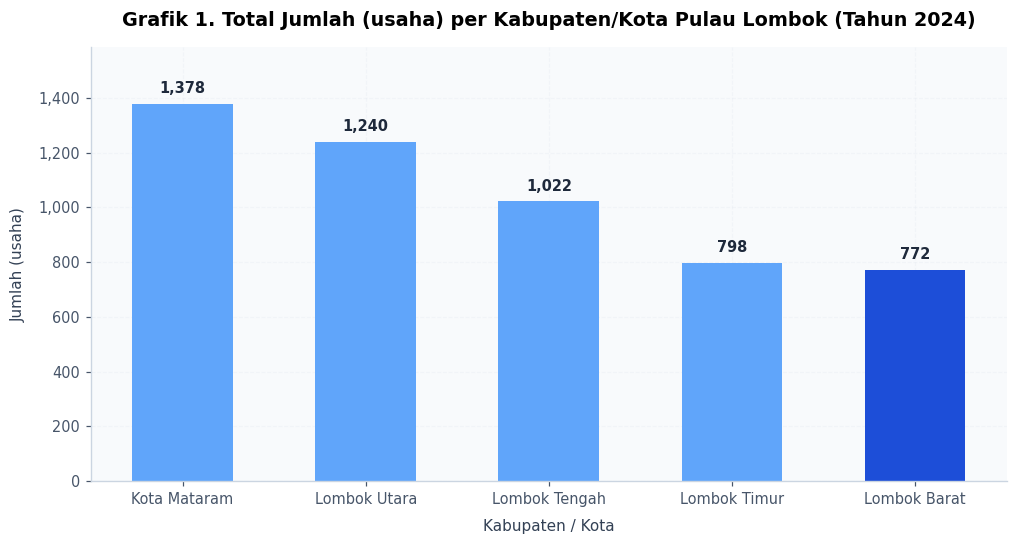

  [OK] Grafik tersimpan -> uts_dam_2501010176/docs/charts/grafik1_total_per_wilayah.png
Interpretasi: Tertinggi di Kota Mataram (1,378 usaha) dan terendah di Lombok Barat (772 usaha).

--------------------------------------------------------------------------------


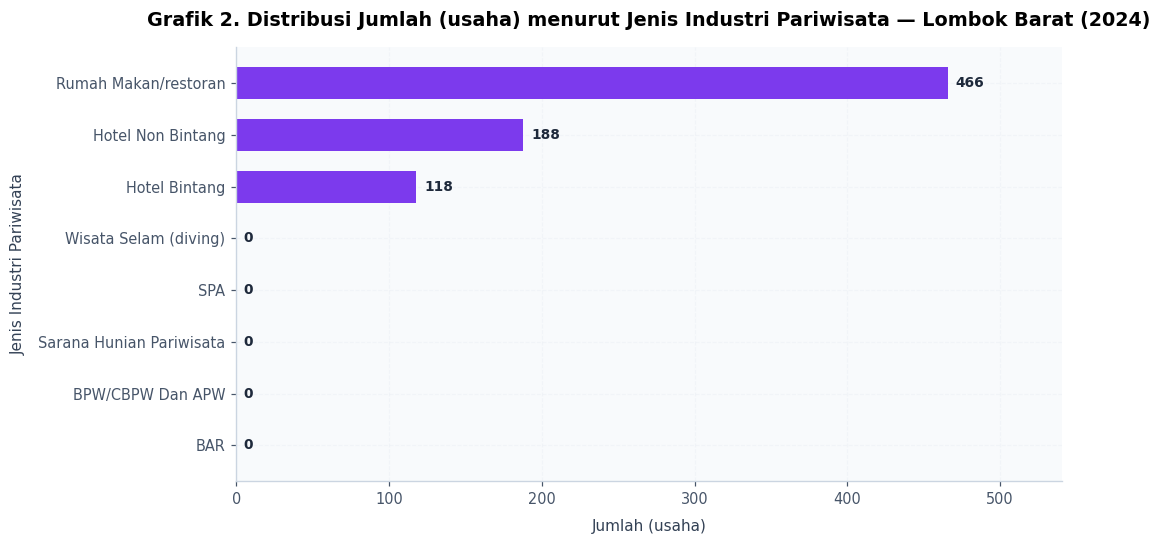

  [OK] Grafik tersimpan -> uts_dam_2501010176/docs/charts/grafik2_distribusi_kategori.png
Interpretasi: Kategori terbesar di Lombok Barat adalah 'Rumah Makan/restoran' (466 usaha) dari total 772 usaha.

--------------------------------------------------------------------------------


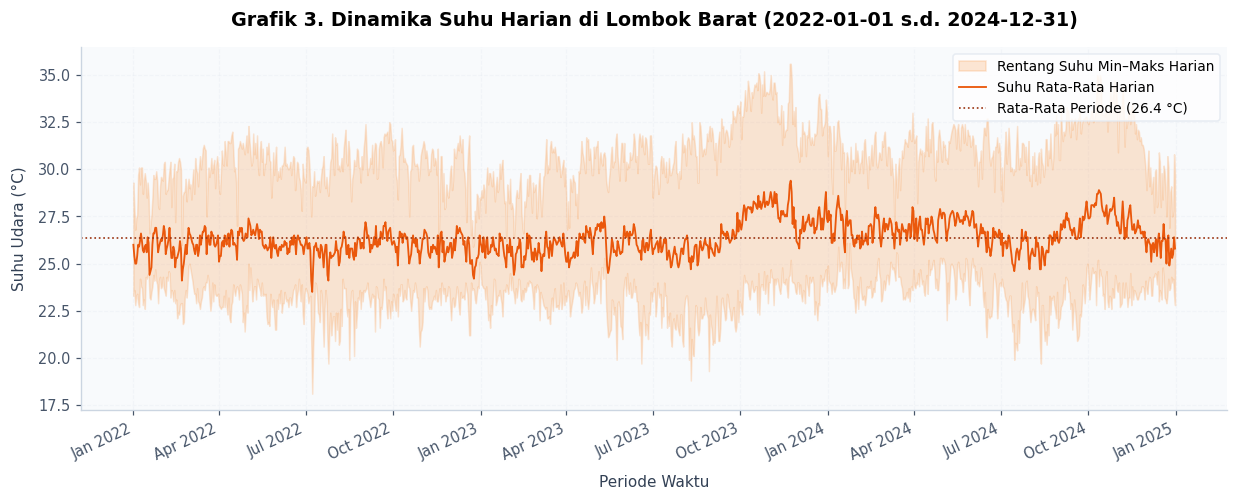

  [OK] Grafik tersimpan -> uts_dam_2501010176/docs/charts/grafik3_suhu_harian.png
Interpretasi: Suhu rata-rata harian berkisar 23.5–29.4 °C (rata-rata keseluruhan 26.4 °C).

--------------------------------------------------------------------------------


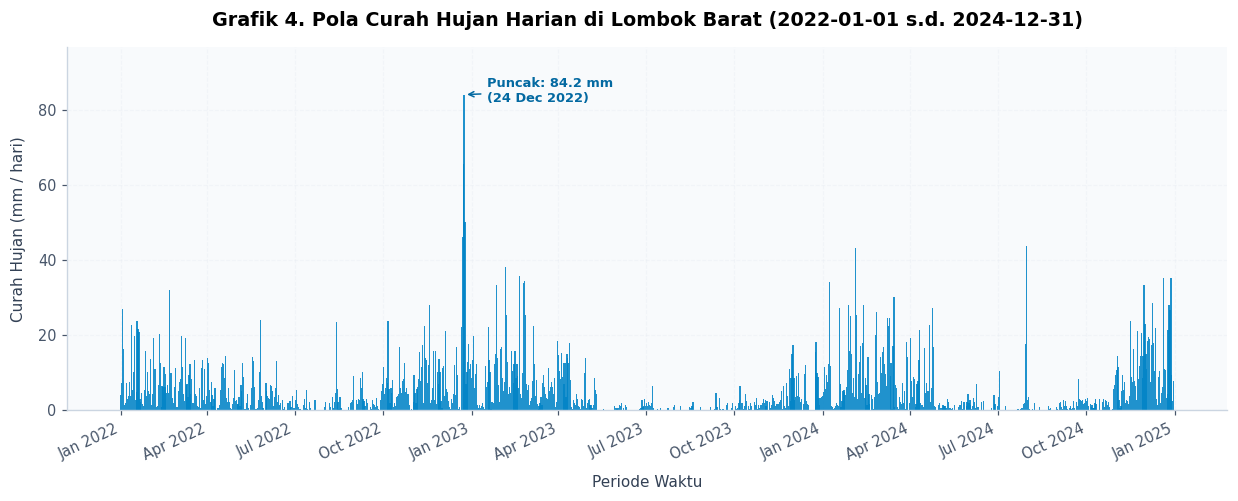

  [OK] Grafik tersimpan -> uts_dam_2501010176/docs/charts/grafik4_hujan_harian.png
Interpretasi: Terdapat 719 hari hujan (>= 1 mm) dari 1096 hari observasi; puncak hujan 84.2 mm pada 2022-12-24.

--------------------------------------------------------------------------------
TABEL PERBANDINGAN VARIABEL CUACA PER KABUPATEN/KOTA


,suhu_rata2,suhu_maks,suhu_min,total_hujan
kabupaten_kota,,,,
Lombok Barat,26.36,30.72,23.23,5678.9
Lombok Tengah,26.01,30.50,22.96,5400.1
Lombok Timur,25.52,30.28,22.07,6676.4
Lombok Utara,26.88,30.33,24.08,6651.2
Mataram,26.61,30.63,23.57,5469.3


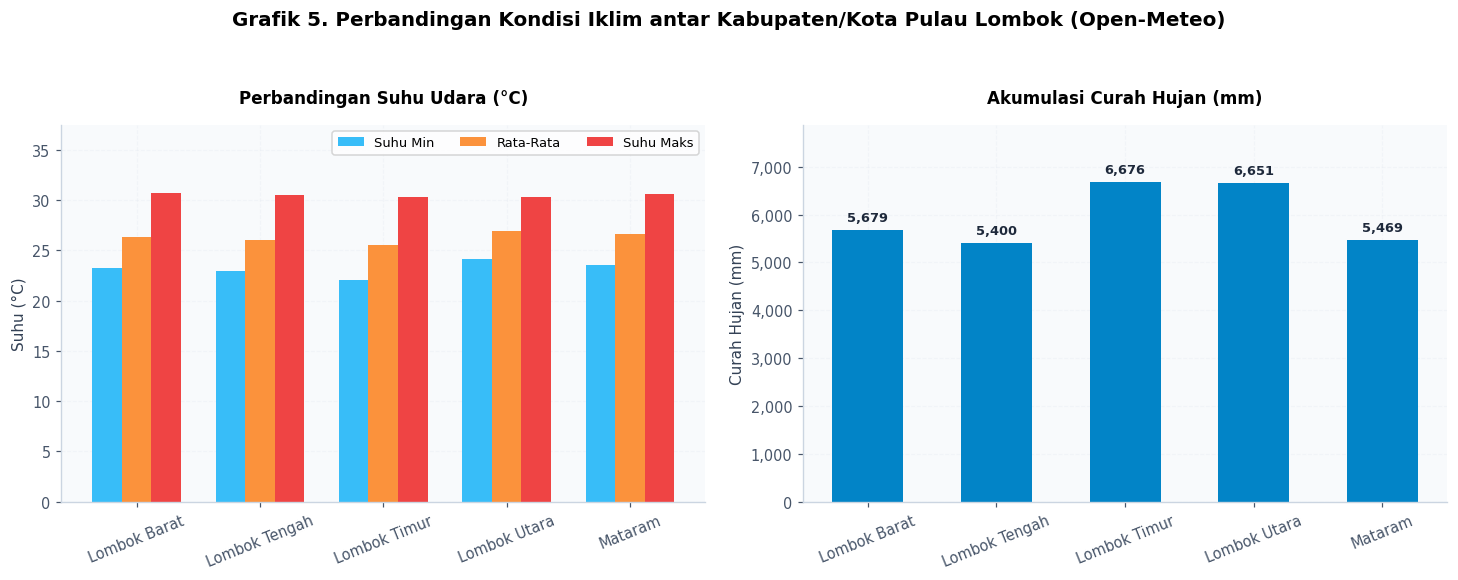

  [OK] Grafik tersimpan -> uts_dam_2501010176/docs/charts/grafik5_perbandingan_cuaca.png
Interpretasi: Suhu rata-rata tertinggi di Lombok Utara (26.9 °C) dan terendah di Lombok Timur (25.5 °C); hujan terbanyak di Lombok Timur (6,676 mm).

--------------------------------------------------------------------------------


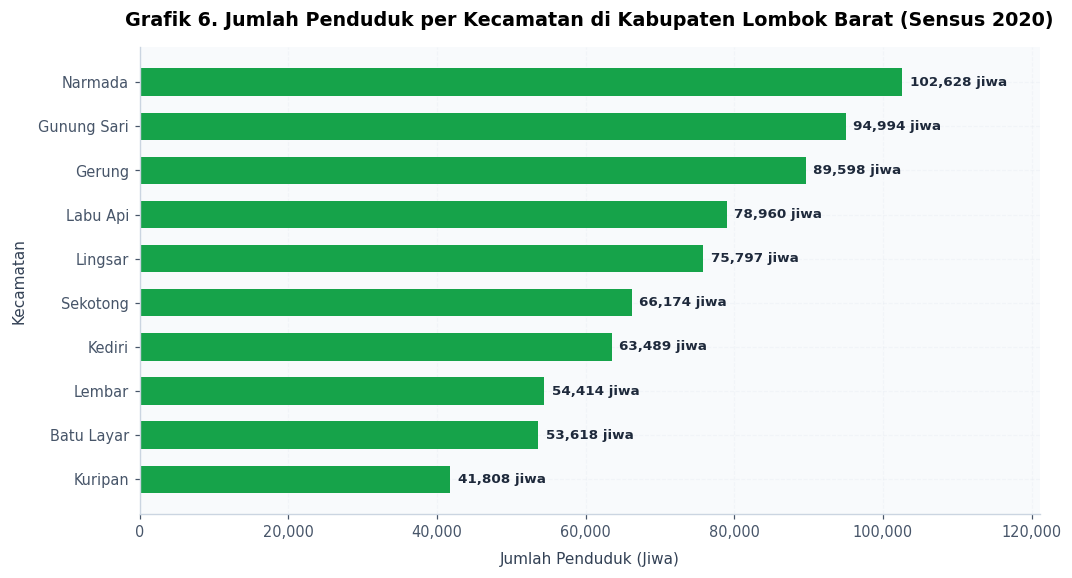

  [OK] Grafik tersimpan -> uts_dam_2501010176/docs/charts/grafik6_penduduk_kecamatan_lombok_barat.png
Interpretasi: Penduduk terbanyak di Narmada (102,628 jiwa) dan paling sedikit di Kuripan (41,808 jiwa); total 721,480 jiwa.

SELESAI VISUALISASI | Total Grafik Tersimpan: 6 berkas di uts_dam_2501010176/docs/charts


In [90]:
# ==============================================================================
# ANALISIS DESKRIPTIF & VISUALISASI DATA TERINTEGRASI (TAMPILAN PREMIUM & RAPI)
# ==============================================================================
import re
from pathlib import Path

import matplotlib
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import pandas as pd

try:
    display
except NameError:
    display = print

# ==============================================================================
# 1. KONFIGURASI DIREKTORI, GAYA VISUAL GLOBAL, & FUNGSI UTILITAS
# ==============================================================================
BASE_DIR = Path("uts_dam_2501010176")
PROC     = BASE_DIR / "data/processed"
DOCS     = BASE_DIR / "docs"
CHARTS   = DOCS / "charts"
CHARTS.mkdir(parents=True, exist_ok=True)

# Gaya visual modern dan bersih
plt.rcParams.update({
    "figure.dpi"        : 110,
    "figure.facecolor"  : "white",
    "axes.facecolor"    : "#f8fafc",
    "axes.edgecolor"    : "#cbd5e1",
    "axes.linewidth"    : 0.9,
    "axes.grid"         : True,
    "grid.color"        : "#e2e8f0",
    "grid.linestyle"    : "--",
    "grid.linewidth"    : 0.7,
    "axes.spines.top"   : False,
    "axes.spines.right" : False,
    "axes.titlesize"    : 12.5,
    "axes.titleweight"  : "bold",
    "axes.titlepad"     : 14,
    "axes.labelsize"    : 10,
    "axes.labelcolor"   : "#334155",
    "xtick.labelsize"   : 9.5,
    "ytick.labelsize"   : 9.5,
    "xtick.color"       : "#475569",
    "ytick.color"       : "#475569",
    "font.family"       : "sans-serif",
})

def norm_wilayah(teks):
    s = re.sub(r"\b(?:kabupaten|kab\.?|kota|regency|city)\b", "", str(teks).lower().strip())
    s = re.sub(r"[^a-z0-9 ]", " ", s)
    return re.sub(r"\s+", " ", s).strip()

FOKUS_WILAYAH = "Lombok Barat"
KUNCI_FOKUS   = norm_wilayah(FOKUS_WILAYAH)
LOMBOK_KEYS   = globals().get(
    "LOMBOK_KEYS",
    {"lombok barat", "lombok tengah", "lombok timur", "lombok utara", "mataram"},
)
NAMA_WILAYAH  = {
    "mataram"      : "Kota Mataram",
    "lombok barat" : "Lombok Barat",
    "lombok tengah": "Lombok Tengah",
    "lombok timur" : "Lombok Timur",
    "lombok utara" : "Lombok Utara",
}
grafik_dibuat = []

def simpan_grafik(fig, nama):
    """Menyimpan grafik PNG 150 DPI dengan tata letak lega dan menampilkannya."""
    path = CHARTS / nama
    fig.tight_layout(pad=1.6)
    fig.savefig(path, dpi=150, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)
    grafik_dibuat.append(str(path))
    print(f"  [OK] Grafik tersimpan -> {path}")

def format_ribuan(ax, sumbu="y"):
    """Menambahkan pemisah ribuan koma pada sumbu angka."""
    fmt = ticker.StrMethodFormatter("{x:,.0f}")
    if sumbu == "y":
        ax.yaxis.set_major_formatter(fmt)
    else:
        ax.xaxis.set_major_formatter(fmt)

def pilih_kolom_nilai(df, abaikan=()):
    kandidat = [
        c for c in df.select_dtypes("number").columns
        if c not in abaikan
        and not re.search(r"kode|code|\bid\b|tahun|year|^no$|urut|cuaca_|wiki_", str(c).lower())
    ]
    pref = [c for c in kandidat if re.search(r"jumlah|usaha|unit|total|banyak", str(c).lower())]
    return (pref or kandidat or [None])[0]

def tahun_bernilai(df, kol_nilai):
    if "tahun_kunci" not in df.columns:
        return None
    per_tahun = df.groupby("tahun_kunci")[kol_nilai].sum()
    ada       = per_tahun[per_tahun > 0]
    return int(ada.index.max()) if len(ada) else int(per_tahun.index.max())

kol_nilai, tahun_pakai, ringkasan = None, None, None

# ==============================================================================
# 2. TABEL RINGKASAN LINTAS VARIABEL PER KABUPATEN/KOTA PULAU LOMBOK
# ==============================================================================
print("=" * 80)
print("TABEL 1: RINGKASAN TERPADU PER KABUPATEN/KOTA PULAU LOMBOK")
print("=" * 80)
try:
    if globals().get("GABUNG_OK", False):
        dasar = df_gabungan.copy()
        if globals().get("CSV_SIAP", False):
            kol_nilai = pilih_kolom_nilai(dasar, abaikan=("tahun_kunci",))
            if kol_nilai and globals().get("MODE_WAKTU") == "tahun":
                tahun_pakai = tahun_bernilai(dasar, kol_nilai)
                dasar       = dasar[dasar["tahun_kunci"] == tahun_pakai]

        grup                 = dasar.groupby("kunci_wilayah")
        ringkasan            = pd.DataFrame(index=sorted(LOMBOK_KEYS))
        ringkasan.index.name = "kunci_wilayah"

        if globals().get("CSV_SIAP", False) and kol_nilai:
            ringkasan[f"total_{kol_nilai}"] = grup[kol_nilai].sum()

        for kol in ("cuaca_rata_suhu_c", "cuaca_total_hujan_mm", "cuaca_hari_hujan", "wiki_kecamatan_terdata"):
            if kol in dasar.columns:
                ringkasan[kol] = grup[kol].first()

        ringkasan = ringkasan.reset_index()
        ringkasan.insert(0, "kabupaten_kota", ringkasan["kunci_wilayah"].map(NAMA_WILAYAH))
        ringkasan.to_csv(PROC / "ringkasan_per_wilayah.csv", index=False)

        judul_tbl = f"Data CSV Tahun {tahun_pakai}" if tahun_pakai else "Seluruh Periode"
        print(f"Cakupan Tabel: {judul_tbl} (Disimpan ke: data/processed/ringkasan_per_wilayah.csv)")
        display(ringkasan.drop(columns="kunci_wilayah"))
    else:
        print("[LEWATI] Tabel ringkasan dilewati karena penggabungan belum berhasil.")
except Exception as err:
    print(f"[GAGAL] Tabel ringkasan dilewati ({type(err).__name__}): {err}")

# ==============================================================================
# 3. GRAFIK 1: TOTAL USAHA PARIWISATA PER KABUPATEN/KOTA LOMBOK
# ==============================================================================
print("\n" + "-" * 80)
try:
    if ringkasan is not None and kol_nilai and f"total_{kol_nilai}" in ringkasan.columns:
        d       = ringkasan.sort_values(f"total_{kol_nilai}", ascending=False)
        fig, ax = plt.subplots(figsize=(9.5, 5.2))
        ax.set_axisbelow(True)

        # Sorot wilayah fokus dengan warna berbeda agar menonjol
        warna_batang = [
            "#1d4ed8" if w == "Lombok Barat" else "#60a5fa"
            for w in d["kabupaten_kota"]
        ]
        batang = ax.bar(d["kabupaten_kota"], d[f"total_{kol_nilai}"], color=warna_batang, width=0.55, edgecolor="none")

        # Beri ruang atas 15% agar label angka tidak menabrak judul
        maks_y = d[f"total_{kol_nilai}"].max()
        ax.set_ylim(0, maks_y * 1.15 if maks_y > 0 else 10)
        format_ribuan(ax, "y")

        for b in batang:
            tinggi = b.get_height()
            ax.annotate(
                f"{tinggi:,.0f}",
                xy=(b.get_x() + b.get_width() / 2, tinggi),
                xytext=(0, 5),
                textcoords="offset points",
                ha="center",
                va="bottom",
                fontsize=9.5,
                fontweight="bold",
                color="#1e293b",
            )

        ax.set_title(
            f"Grafik 1. Total {kol_nilai} per Kabupaten/Kota Pulau Lombok"
            + (f" (Tahun {tahun_pakai})" if tahun_pakai else "")
        )
        ax.set_xlabel("Kabupaten / Kota", labelpad=8)
        ax.set_ylabel(f"{kol_nilai}" + ("" if "(" in str(kol_nilai) else " (Satuan: Usaha)"), labelpad=8)
        simpan_grafik(fig, "grafik1_total_per_wilayah.png")
        print(
            f"Interpretasi: Tertinggi di {d.iloc[0]['kabupaten_kota']} ({d.iloc[0][f'total_{kol_nilai}']:,.0f} usaha) "
            f"dan terendah di {d.iloc[-1]['kabupaten_kota']} ({d.iloc[-1][f'total_{kol_nilai}']:,.0f} usaha)."
        )
    else:
        print("[LEWATI] Grafik 1 dilewati.")
except Exception as err:
    print(f"[GAGAL] Grafik 1 dilewati ({type(err).__name__}): {err}")

# ==============================================================================
# 4. GRAFIK 2: DISTRIBUSI KATEGORI USAHA PARIWISATA (WILAYAH FOKUS)
# ==============================================================================
print("\n" + "-" * 80)
try:
    if globals().get("CSV_SIAP", False) and globals().get("GABUNG_OK", False) and kol_nilai:
        dc = df_gabungan[df_gabungan["kunci_wilayah"] == KUNCI_FOKUS]
        if "tahun_kunci" in dc.columns and len(dc):
            thn = tahun_bernilai(dc, kol_nilai)
            dc  = dc[dc["tahun_kunci"] == thn]
        else:
            thn = None

        kat_kandidat = [
            c for c in dc.select_dtypes(exclude="number").columns
            if c not in (CSV_KOLOM_WILAYAH, CSV_KOLOM_WAKTU, "kunci_wilayah", "wiki_daftar_kecamatan")
            and not re.search(r"kode|provinsi|kabupaten|kota", str(c).lower())
            and 2 <= dc[c].nunique() <= 40
        ]
        pref    = [c for c in kat_kandidat if re.search(r"jenis|kategori|klasifikasi|usaha", str(c).lower())]
        kol_kat = (pref or kat_kandidat or [None])[0]

        if len(dc) and kol_kat:
            komposisi   = dc.groupby(kol_kat)[kol_nilai].sum().sort_values()
            tinggi_fig  = max(5.2, len(komposisi) * 0.45)
            fig, ax     = plt.subplots(figsize=(10, tinggi_fig))
            ax.set_axisbelow(True)

            batang = ax.barh(komposisi.index.astype(str), komposisi.values, color="#7c3aed", height=0.62)
            maks_x = komposisi.max()
            ax.set_xlim(0, maks_x * 1.16 if maks_x > 0 else 10)
            format_ribuan(ax, "x")

            for b in batang:
                lebar = b.get_width()
                ax.annotate(
                    f"{lebar:,.0f}",
                    xy=(lebar, b.get_y() + b.get_height() / 2),
                    xytext=(5, 0),
                    textcoords="offset points",
                    ha="left",
                    va="center",
                    fontsize=9,
                    fontweight="bold",
                    color="#1e293b",
                )

            ax.set_title(
                f"Grafik 2. Distribusi {kol_nilai} menurut {kol_kat} — {FOKUS_WILAYAH}"
                + (f" ({thn})" if thn else "")
            )
            ax.set_xlabel(f"{kol_nilai}" + ("" if "(" in str(kol_nilai) else " (Satuan: Usaha)"), labelpad=8)
            ax.set_ylabel(str(kol_kat), labelpad=8)
            simpan_grafik(fig, "grafik2_distribusi_kategori.png")
            print(
                f"Interpretasi: Kategori terbesar di {FOKUS_WILAYAH} adalah '{komposisi.index[-1]}' "
                f"({komposisi.iloc[-1]:,.0f} usaha) dari total {komposisi.sum():,.0f} usaha."
            )
        else:
            print(f"[LEWATI] Grafik 2 dilewati.")
    else:
        print("[LEWATI] Grafik 2 dilewati.")
except Exception as err:
    print(f"[GAGAL] Grafik 2 dilewati ({type(err).__name__}): {err}")

# ==============================================================================
# 5. GRAFIK 3: TREN SUHU HARIAN (WILAYAH FOKUS)
# ==============================================================================
print("\n" + "-" * 80)
try:
    if globals().get("API_OK", False):
        fk      = df_api_bersih[df_api_bersih["kunci_wilayah"] == KUNCI_FOKUS].sort_values("tanggal")
        fig, ax = plt.subplots(figsize=(11.5, 4.8))
        ax.set_axisbelow(True)

        ax.fill_between(
            fk["tanggal"], fk["suhu_min_c"], fk["suhu_maks_c"],
            alpha=0.22, color="#fb923c", label="Rentang Suhu Min–Maks Harian"
        )
        ax.plot(
            fk["tanggal"], fk["suhu_rata2_c"],
            color="#ea580c", linewidth=1.2, label="Suhu Rata-Rata Harian"
        )
        rata_suhu = fk["suhu_rata2_c"].mean()
        ax.axhline(
            rata_suhu, color="#9a3412", linestyle=":", linewidth=1.1,
            label=f"Rata-Rata Periode ({rata_suhu:.1f} °C)"
        )

        ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
        plt.setp(ax.get_xticklabels(), rotation=25, ha="right")

        ax.set_title(f"Grafik 3. Dinamika Suhu Harian di {FOKUS_WILAYAH} ({API_MULAI} s.d. {API_AKHIR})")
        ax.set_xlabel("Periode Waktu", labelpad=8)
        ax.set_ylabel("Suhu Udara (°C)", labelpad=8)
        ax.legend(frameon=True, facecolor="white", edgecolor="#e2e8f0", loc="upper right", fontsize=9)
        simpan_grafik(fig, "grafik3_suhu_harian.png")
        print(
            f"Interpretasi: Suhu rata-rata harian berkisar {fk['suhu_rata2_c'].min():.1f}–{fk['suhu_rata2_c'].max():.1f} °C "
            f"(rata-rata keseluruhan {rata_suhu:.1f} °C)."
        )
    else:
        print("[LEWATI] Grafik 3 dilewati.")
except Exception as err:
    print(f"[GAGAL] Grafik 3 dilewati ({type(err).__name__}): {err}")

# ==============================================================================
# 6. GRAFIK 4: POLA CURAH HUJAN HARIAN (WILAYAH FOKUS)
# ==============================================================================
print("\n" + "-" * 80)
try:
    if globals().get("API_OK", False):
        fk      = df_api_bersih[df_api_bersih["kunci_wilayah"] == KUNCI_FOKUS].sort_values("tanggal")
        fig, ax = plt.subplots(figsize=(11.5, 4.8))
        ax.set_axisbelow(True)

        ax.bar(fk["tanggal"], fk["curah_hujan_mm"], width=1.2, color="#0284c7", alpha=0.88)

        # Tandai puncak hujan tertinggi agar informatif
        puncak = fk.loc[fk["curah_hujan_mm"].idxmax()]
        ax.annotate(
            f"Puncak: {puncak['curah_hujan_mm']:.1f} mm\n({puncak['tanggal'].strftime('%d %b %Y')})",
            xy=(puncak["tanggal"], puncak["curah_hujan_mm"]),
            xytext=(15, -5),
            textcoords="offset points",
            fontsize=8.5,
            fontweight="bold",
            color="#0369a1",
            arrowprops=dict(arrowstyle="->", color="#0369a1", lw=1),
        )

        ax.set_ylim(0, fk["curah_hujan_mm"].max() * 1.15)
        ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
        plt.setp(ax.get_xticklabels(), rotation=25, ha="right")

        ax.set_title(f"Grafik 4. Pola Curah Hujan Harian di {FOKUS_WILAYAH} ({API_MULAI} s.d. {API_AKHIR})")
        ax.set_xlabel("Periode Waktu", labelpad=8)
        ax.set_ylabel("Curah Hujan (mm / hari)", labelpad=8)
        simpan_grafik(fig, "grafik4_hujan_harian.png")

        hari_hujan = int((fk["curah_hujan_mm"] >= 1).sum())
        print(
            f"Interpretasi: Terdapat {hari_hujan} hari hujan (>= 1 mm) dari {len(fk)} hari observasi; "
            f"puncak hujan {puncak['curah_hujan_mm']:.1f} mm pada {puncak['tanggal'].date()}."
        )
    else:
        print("[LEWATI] Grafik 4 dilewati.")
except Exception as err:
    print(f"[GAGAL] Grafik 4 dilewati ({type(err).__name__}): {err}")

# ==============================================================================
# 7. GRAFIK 5: PERBANDINGAN VARIABEL CUACA ANTAR KABUPATEN/KOTA
# ==============================================================================
print("\n" + "-" * 80)
try:
    if globals().get("API_OK", False):
        rata = df_api_bersih.groupby("kabupaten_kota").agg(
            suhu_rata2 =("suhu_rata2_c", "mean"),
            suhu_maks  =("suhu_maks_c", "mean"),
            suhu_min   =("suhu_min_c", "mean"),
            total_hujan=("curah_hujan_mm", "sum"),
        )
        print("TABEL PERBANDINGAN VARIABEL CUACA PER KABUPATEN/KOTA")
        display(rata.round(2))

        fig, (a1, a2) = plt.subplots(1, 2, figsize=(13.5, 5.2))
        a1.set_axisbelow(True)
        a2.set_axisbelow(True)

        # Panel Kiri: Suhu Min, Rata-rata, Maks
        df_suhu_plot = rata[["suhu_min", "suhu_rata2", "suhu_maks"]].rename(
            columns={"suhu_min": "Suhu Min", "suhu_rata2": "Rata-Rata", "suhu_maks": "Suhu Maks"}
        )
        df_suhu_plot.plot(
            kind="bar", ax=a1, width=0.72,
            color=["#38bdf8", "#fb923c", "#ef4444"], edgecolor="none"
        )
        a1.set_ylim(0, df_suhu_plot.values.max() * 1.22)
        a1.set_title("Perbandingan Suhu Udara (°C)", fontsize=11)
        a1.set_xlabel("")
        a1.set_ylabel("Suhu (°C)")
        a1.tick_params(axis="x", rotation=22)
        a1.legend(ncol=3, fontsize=8.5, frameon=True, facecolor="white", loc="upper right")

        # Panel Kanan: Total Curah Hujan dengan label angka di atas batang
        batang_hujan = a2.bar(rata.index, rata["total_hujan"], color="#0284c7", width=0.55)
        a2.set_ylim(0, rata["total_hujan"].max() * 1.18)
        format_ribuan(a2, "y")
        for b in batang_hujan:
            h = b.get_height()
            a2.annotate(
                f"{h:,.0f}",
                xy=(b.get_x() + b.get_width() / 2, h),
                xytext=(0, 4),
                textcoords="offset points",
                ha="center", va="bottom", fontsize=8.5, fontweight="bold", color="#1e293b"
            )
        a2.set_title("Akumulasi Curah Hujan (mm)", fontsize=11)
        a2.set_xlabel("")
        a2.set_ylabel("Curah Hujan (mm)")
        a2.tick_params(axis="x", rotation=22)

        fig.suptitle(
            "Grafik 5. Perbandingan Kondisi Iklim antar Kabupaten/Kota Pulau Lombok (Open-Meteo)",
            fontsize=13, fontweight="bold", y=1.02
        )
        simpan_grafik(fig, "grafik5_perbandingan_cuaca.png")
        print(
            f"Interpretasi: Suhu rata-rata tertinggi di {rata['suhu_rata2'].idxmax()} ({rata['suhu_rata2'].max():.1f} °C) "
            f"dan terendah di {rata['suhu_rata2'].idxmin()} ({rata['suhu_rata2'].min():.1f} °C); "
            f"hujan terbanyak di {rata['total_hujan'].idxmax()} ({rata['total_hujan'].max():,.0f} mm)."
        )
    else:
        print("[LEWATI] Grafik 5 dilewati.")
except Exception as err:
    print(f"[GAGAL] Grafik 5 dilewati ({type(err).__name__}): {err}")

# ==============================================================================
# 8. GRAFIK 6: JUMLAH PENDUDUK PER KECAMATAN LOMBOK BARAT (WIKIPEDIA)
# ==============================================================================
print("\n" + "-" * 80)
try:
    if globals().get("LOBAR_OK", False):
        dl      = df_lobar.sort_values("penduduk_2020")
        fig, ax = plt.subplots(figsize=(10, 5.5))
        ax.set_axisbelow(True)

        batang = ax.barh(dl["kecamatan"], dl["penduduk_2020"], color="#16a34a", height=0.62)
        maks_x = dl["penduduk_2020"].max()
        ax.set_xlim(0, maks_x * 1.18)
        format_ribuan(ax, "x")

        for b in batang:
            lebar = b.get_width()
            ax.annotate(
                f"{lebar:,.0f} jiwa",
                xy=(lebar, b.get_y() + b.get_height() / 2),
                xytext=(5, 0),
                textcoords="offset points",
                ha="left", va="center", fontsize=8.8, fontweight="bold", color="#1e293b"
            )

        ax.set_title("Grafik 6. Jumlah Penduduk per Kecamatan di Kabupaten Lombok Barat (Sensus 2020)")
        ax.set_xlabel("Jumlah Penduduk (Jiwa)", labelpad=8)
        ax.set_ylabel("Kecamatan", labelpad=8)
        simpan_grafik(fig, "grafik6_penduduk_kecamatan_lombok_barat.png")
        print(
            f"Interpretasi: Penduduk terbanyak di {dl.iloc[-1]['kecamatan']} ({dl.iloc[-1]['penduduk_2020']:,} jiwa) "
            f"dan paling sedikit di {dl.iloc[0]['kecamatan']} ({dl.iloc[0]['penduduk_2020']:,} jiwa); "
            f"total {dl['penduduk_2020'].sum():,} jiwa."
        )
    else:
        print("[LEWATI] Grafik 6 dilewati.")
except Exception as err:
    print(f"[GAGAL] Grafik 6 dilewati ({type(err).__name__}): {err}")

print("\n" + "=" * 80)
print(f"SELESAI VISUALISASI | Total Grafik Tersimpan: {len(grafik_dibuat)} berkas di {CHARTS}")
print("=" * 80)

## Kesimpulan dan Implikasi Hasil Analisis

Bagian ini menyusun ringkasan otomatis dari seluruh rangkaian akuisisi multi-sumber (CSV Satu Data NTB, Open-Meteo API, dan *web scraping* Wikipedia), validasi integrasi relasional, serta catatan keterbatasan data untuk kajian pariwisata dan lingkungan di Pulau Lombok.

In [91]:
# ==============================================================================
# KESIMPULAN AKHIR & CATATAN KETERBATASAN DATA
# ==============================================================================
print("=" * 80)
print("KESIMPULAN AKHIR PROYEK AKUISISI & PENGELOLAAN DATA PULAU LOMBOK")
print("=" * 80)

try:
    # 1. Kesimpulan Dataset CSV
    if globals().get("CSV_SIAP", False):
        print(
            f"1. Dataset CSV : Berhasil mengunduh dataset dari '{CSV_PORTAL}' "
            f"({len(df_csv_mentah):,} baris x {df_csv_mentah.shape[1]} kolom; satuan: {CSV_SATUAN}). "
            f"Lisensi tercatat: {CSV_LISENSI}."
        )
    else:
        print("1. Dataset CSV : Belum berhasil disiapkan sehingga bagian ini belum dapat disimpulkan.")

    # 2. Kesimpulan API Open-Meteo
    if globals().get("API_OK", False):
        fk = df_api_bersih[df_api_bersih["kunci_wilayah"] == KUNCI_FOKUS]
        print(
            f"2. Data API    : Memperoleh {len(df_api_bersih):,} baris cuaca harian untuk 5 kabupaten/kota "
            f"dari Open-Meteo. Di {FOKUS_WILAYAH}, suhu rata-rata harian mencapai {fk['suhu_rata2_c'].mean():.1f} °C "
            f"dengan akumulasi curah hujan {fk['curah_hujan_mm'].sum():,.0f} mm ({API_MULAI} s.d. {API_AKHIR})."
        )
    else:
        print("2. Data API    : Data cuaca dari Open-Meteo belum berhasil diperoleh.")

    # 3. Kesimpulan Web Scraping Wikipedia
    if globals().get("WEB_OK", False):
        n_fokus = int(wiki_kab.loc[wiki_kab["kunci_wilayah"] == KUNCI_FOKUS, "wiki_kecamatan_terdata"].iloc[0])
        print(
            f"3. Scraping ID : Mengambil {len(df_kec_semua)} baris kecamatan NTB dari Wikipedia Indonesia "
            f"({n_fokus} kecamatan tercatat untuk {FOKUS_WILAYAH}); status robots.txt = {hasil_kepatuhan['boleh_diakses']}."
        )
    else:
        print("3. Scraping ID : Scraping daftar kecamatan NTB belum berhasil dilakukan.")

    if globals().get("LOBAR_OK", False):
        print(
            f"   Scraping EN : Mengambil {len(df_lobar)} kecamatan dari halaman Wikipedia West Lombok Regency "
            f"dengan total penduduk Sensus 2020 sebesar {int(df_lobar['penduduk_2020'].sum()):,} jiwa."
        )

    # 4. Kesimpulan Penggabungan (Merge)
    if globals().get("GABUNG_OK", False):
        print(
            f"4. Integrasi   : Berhasil menggabungkan {sumber_dipakai} pada kunci {kunci_gabung} "
            f"(validate='many_to_one') menghasilkan {len(df_gabungan):,} baris x {df_gabungan.shape[1]} kolom tanpa duplikasi."
        )

    # 5. Catatan Keterbatasan Data
    print("\n" + "-" * 80)
    print("KETERBATASAN DATA YANG PERLU DICATAT:")
    print("-" * 80)
    print("  * Data cuaca Open-Meteo berasal dari model reanalisis grid (satu titik koordinat per wilayah), bukan stasiun fisik.")
    print("  * Daftar kecamatan Wikipedia disunting oleh sukarelawan sehingga berpotensi tertinggal dari pemekaran wilayah terbaru.")
    print("  * Dataset resmi portal pemerintah dapat memuat nilai 0 atau blok baris berulang (duplikat persis telah dibuang saat pembersihan).")
    print("=" * 80)

except Exception as err:
    print(f"[GAGAL] Kesimpulan tidak dapat disusun ({type(err).__name__}): {err}")

KESIMPULAN AKHIR PROYEK AKUISISI & PENGELOLAAN DATA PULAU LOMBOK
1. Dataset CSV : Berhasil mengunduh dataset dari 'Satu Data NTB (data.ntbprov.go.id), Dinas Pariwisata Provinsi NTB' (480 baris x 9 kolom; satuan: usaha (jumlah usaha industri pariwisata per jenis usaha); data tahunan periode 2022-2024). Lisensi tercatat: License Not Specified.
2. Data API    : Memperoleh 5,480 baris cuaca harian untuk 5 kabupaten/kota dari Open-Meteo. Di Lombok Barat, suhu rata-rata harian mencapai 26.4 °C dengan akumulasi curah hujan 5,679 mm (2022-01-01 s.d. 2024-12-31).
3. Scraping ID : Mengambil 117 baris kecamatan NTB dari Wikipedia Indonesia (10 kecamatan tercatat untuk Lombok Barat); status robots.txt = True.
   Scraping EN : Mengambil 10 kecamatan dari halaman Wikipedia West Lombok Regency dengan total penduduk Sensus 2020 sebesar 721,480 jiwa.
4. Integrasi   : Berhasil menggabungkan ['csv', 'api', 'scraping'] pada kunci ['kunci_wilayah', 'tahun_kunci'] (validate='many_to_one') menghasilkan 240 b

## Silsilah Data (*Data Provenance*) dan Rekap Pemeriksaan Akhir UTS

Guna menjamin akuntabilitas akademis dan keterlacakan data (*auditability*), bagian akhir ini menjalankan dua proses verifikasi utama:
1. **Dokumentasi Provenance (`docs/provenance.csv`):** Mencatat riwayat seluruh berkas mentah (*raw files*) di direktori `data/raw/` beserta URL sumber asli, metode akuisisi, waktu akses, lisensi, ukuran berkas, dan sidik jari digital **MD5 Cryptographic Hash**.
2. **Audit Kelengkapan Rubrik (`docs/rekap_pemeriksaan_akhir.csv`):** Mengevaluasi status kelulusan seluruh 11 indikator persyaratan UTS BIFP-243 serta menampilkan daftar lengkap berkas proyek siap kumpul ke ELSA.

In [92]:
# ==============================================================================
# SILSILAH DATA (DATA PROVENANCE) & REKAP PEMERIKSAAN AKHIR PERSYARATAN UTS
# ==============================================================================
import hashlib
import json
from datetime import datetime, timezone
from pathlib import Path

import pandas as pd

try:
    display
except NameError:
    display = print

# ==============================================================================
# 1. KONFIGURASI DIREKTORI, IDENTITAS, & PENGAMAN VARIABEL MEMORI
# ==============================================================================
BASE_DIR = Path("uts_dam_2501010176")
RAW      = BASE_DIR / "data/raw"
PROC     = BASE_DIR / "data/processed"
DOCS     = BASE_DIR / "docs"
CHARTS   = DOCS / "charts"
for d in (RAW, PROC, DOCS, CHARTS):
    d.mkdir(parents=True, exist_ok=True)

NAMA         = globals().get("NAMA", "Ni Kadek Rahayu Windari")
NIM          = globals().get("NIM", "2501010176")
EMAIL_KAMPUS = globals().get("EMAIL_KAMPUS", "2501010176@instiki.ac.id")
UA           = globals().get("UA", f"INSTIKI-BIFP243-UTS/1.0 ({EMAIL_KAMPUS})")
TIMEOUT      = globals().get("TIMEOUT", 15)
JEDA         = globals().get("JEDA", 1.5)

def hitung_md5(path_file):
    """Menghitung checksum MD5 berkas untuk verifikasi integritas provenance."""
    h = hashlib.md5()
    with open(path_file, "rb") as f:
        for chunk in iter(lambda: f.read(8192), b""):
            h.update(chunk)
    return h.hexdigest()

waktu_akses = globals().get("waktu_akses", {})
def ambil_waktu_berkas(p, fallback=""):
    p = Path(p)
    if p.name in waktu_akses:
        return waktu_akses[p.name]
    if p.exists():
        return datetime.fromtimestamp(p.stat().st_mtime, tz=timezone.utc).isoformat()
    return fallback

def slug(nama):
    return nama.lower().replace(" ", "_")

# Pengaman Dataset CSV (Soal 1)
daftar_csv_raw = sorted(RAW.glob("*.csv"), key=lambda p: p.stat().st_mtime)
path_csv       = globals().get("path_csv", daftar_csv_raw[-1] if daftar_csv_raw else None)
df_csv_mentah  = globals().get("df_csv_mentah", None)
if df_csv_mentah is None and path_csv and Path(path_csv).exists():
    try:
        df_csv_mentah = pd.read_csv(path_csv)
    except Exception:
        df_csv_mentah = pd.read_csv(path_csv, sep=";")

CSV_SIAP              = bool(globals().get("CSV_SIAP", df_csv_mentah is not None and len(df_csv_mentah) >= 100))
CSV_PORTAL            = globals().get("CSV_PORTAL", "Satu Data NTB (data.ntbprov.go.id), Dinas Pariwisata Provinsi NTB")
CSV_URL_SUMBER        = globals().get("CSV_URL_SUMBER", "https://data.ntbprov.go.id/dataset/9f040bf6-9148-42d7-9420-125ee229d599/show")
CSV_URL_UNDUH_DIPAKAI = globals().get("CSV_URL_UNDUH_DIPAKAI", CSV_URL_SUMBER)
CSV_TANGGAL_UNDUH     = globals().get("CSV_TANGGAL_UNDUH", "2026-11-26")
CSV_LISENSI           = globals().get("CSV_LISENSI", "License Not Specified")

# Pengaman Dataset API (Soal 3)
df_api_bersih = globals().get("df_api_bersih", None)
if df_api_bersih is None and (PROC / "api_cuaca_bersih.csv").exists():
    df_api_bersih = pd.read_csv(PROC / "api_cuaca_bersih.csv")

API_OK      = bool(globals().get("API_OK", df_api_bersih is not None and len(df_api_bersih) >= 30))
API_URL     = globals().get("API_URL", "https://archive-api.open-meteo.com/v1/archive")
API_DAILY   = globals().get("API_DAILY", ["temperature_2m_mean", "temperature_2m_max", "temperature_2m_min", "precipitation_sum"])
API_MULAI   = globals().get("API_MULAI", "2022-01-01")
API_AKHIR   = globals().get("API_AKHIR", "2024-12-31")
WILAYAH_API = globals().get("WILAYAH_API", {
    "Lombok Barat" : (-8.717, 116.117),
    "Lombok Tengah": (-8.700, 116.267),
    "Lombok Timur" : (-8.650, 116.533),
    "Lombok Utara" : (-8.350, 116.150),
    "Mataram"      : (-8.583, 116.117),
})

# Pengaman Dataset Web Scraping (Soal 4)
df_kec_semua = globals().get("df_kec_semua", None)
if df_kec_semua is None and (PROC / "scraping_kecamatan_ntb_bersih.csv").exists():
    df_kec_semua = pd.read_csv(PROC / "scraping_kecamatan_ntb_bersih.csv")

df_lobar = globals().get("df_lobar", None)
if df_lobar is None and (PROC / "scraping_kecamatan_lombok_barat.csv").exists():
    df_lobar = pd.read_csv(PROC / "scraping_kecamatan_lombok_barat.csv")

WEB_OK          = bool(globals().get("WEB_OK", df_kec_semua is not None and len(df_kec_semua) > 0))
LOBAR_OK        = bool(globals().get("LOBAR_OK", df_lobar is not None and len(df_lobar) > 0))
TARGET_WEB      = globals().get("TARGET_WEB", "https://id.wikipedia.org/wiki/Daftar_kecamatan_dan_kelurahan_di_Nusa_Tenggara_Barat")
TARGET_LOBAR    = globals().get("TARGET_LOBAR", "https://en.wikipedia.org/wiki/West_Lombok_Regency")
path_html       = globals().get("path_html", RAW / "wikipedia_districts_ntb.html")
path_html_lobar = globals().get("path_html_lobar", RAW / "wikipedia_west_lombok_regency.html")
hasil_kepatuhan = globals().get("hasil_kepatuhan", {"boleh_diakses": True, "robots_url": "https://id.wikipedia.org/robots.txt"})
ROBOTS_OK       = bool(globals().get("ROBOTS_OK", hasil_kepatuhan.get("boleh_diakses", True)))

# Pengaman Dataset Gabungan, Etika, & Grafik (Soal 2 & 5)
df_gabungan = globals().get("df_gabungan", None)
if df_gabungan is None:
    kandidat_merge = sorted(PROC.glob("*gabung*.csv")) + sorted(PROC.glob("*merge*.csv"))
    if kandidat_merge:
        df_gabungan = pd.read_csv(kandidat_merge[-1])

GABUNG_OK      = bool(globals().get("GABUNG_OK", df_gabungan is not None and len(df_gabungan) > 0))
sumber_dipakai = globals().get("sumber_dipakai", ["csv", "api", "scraping"])
kunci_gabung   = globals().get("kunci_gabung", ["kunci_wilayah", "tahun_kunci"])

checklist = globals().get("checklist", None)
if checklist is None and (DOCS / "data_ethics_checklist.csv").exists():
    checklist = pd.read_csv(DOCS / "data_ethics_checklist.csv")

grafik_dibuat = globals().get("grafik_dibuat", sorted(CHARTS.glob("*.png")) if CHARTS.exists() else [])
endpoint_log  = globals().get("endpoint_log", [])

# ==============================================================================
# 2. PENYUSUNAN DOKUMENTASI PROVENANCE (DOCS/PROVENANCE.CSV)
# ==============================================================================
print("=" * 84)
print("BAGIAN 1: DOKUMENTASI SILSILAH BERKAS MENTAH (DATA PROVENANCE)")
print("=" * 84)

baris_prov = []
if CSV_SIAP and path_csv is not None:
    p_csv = Path(path_csv)
    baris_prov.append({
        "Sumber_Data"  : f"Unduh berkas ({CSV_PORTAL})",
        "Metode"       : "Download dataset",
        "Nama_Berkas"  : p_csv.name,
        "URL_Sumber"   : (CSV_URL_UNDUH_DIPAKAI or CSV_URL_SUMBER),
        "Tanggal_Akses": ambil_waktu_berkas(p_csv, CSV_TANGGAL_UNDUH),
        "Lisensi"      : CSV_LISENSI,
        "Path"         : str(p_csv),
    })

if API_OK:
    for nama, (lat, lon) in WILAYAH_API.items():
        f = RAW / f"api_cuaca_{slug(nama)}.json"
        baris_prov.append({
            "Sumber_Data"  : f"Open-Meteo Historical Weather API ({nama})",
            "Metode"       : "API",
            "Nama_Berkas"  : f.name,
            "URL_Sumber"   : (
                f"{API_URL}?latitude={lat}&longitude={lon}"
                f"&start_date={API_MULAI}&end_date={API_AKHIR}"
                f"&daily={','.join(API_DAILY)}&timezone=Asia/Makassar"
            ),
            "Tanggal_Akses": ambil_waktu_berkas(f),
            "Lisensi"      : "CC BY 4.0 (data), gratis untuk non-komersial",
            "Path"         : str(f),
        })

if WEB_OK:
    p_html = Path(path_html)
    baris_prov.append({
        "Sumber_Data"  : "Wikipedia: Daftar kecamatan dan kelurahan di NTB",
        "Metode"       : "Web scraping (statis)",
        "Nama_Berkas"  : p_html.name,
        "URL_Sumber"   : TARGET_WEB,
        "Tanggal_Akses": ambil_waktu_berkas(p_html),
        "Lisensi"      : "CC BY-SA 4.0",
        "Path"         : str(p_html),
    })

if LOBAR_OK:
    p_lobar = Path(path_html_lobar)
    baris_prov.append({
        "Sumber_Data"  : "Wikipedia: West Lombok Regency",
        "Metode"       : "Web scraping (statis)",
        "Nama_Berkas"  : p_lobar.name,
        "URL_Sumber"   : TARGET_LOBAR,
        "Tanggal_Akses": ambil_waktu_berkas(p_lobar),
        "Lisensi"      : "CC BY-SA 4.0",
        "Path"         : str(p_lobar),
    })

for nama_robots, url_robots in (
    ("robots_wikipedia.txt", hasil_kepatuhan.get("robots_url", "https://id.wikipedia.org/robots.txt")),
    ("robots_wikipedia_en.txt", "https://en.wikipedia.org/robots.txt"),
    ("robots_portal_ntb.txt", "https://data.ntbprov.go.id/robots.txt"),
):
    f_rob = RAW / nama_robots
    if f_rob.exists():
        baris_prov.append({
            "Sumber_Data"  : f"Bukti robots.txt ({nama_robots})",
            "Metode"       : "Bukti kepatuhan",
            "Nama_Berkas"  : nama_robots,
            "URL_Sumber"   : url_robots,
            "Tanggal_Akses": ambil_waktu_berkas(f_rob),
            "Lisensi"      : "Kebijakan situs",
            "Path"         : str(f_rob),
        })

baris_prov = [b for b in baris_prov if Path(b["Path"]).exists()]
df_prov    = None

if baris_prov:
    for b in baris_prov:
        p                = Path(b["Path"])
        b["Ukuran_Byte"] = p.stat().st_size
        b["Hash_MD5"]    = hitung_md5(p)
    df_prov = pd.DataFrame(baris_prov).drop(columns="Path")
    df_prov.to_csv(DOCS / "provenance.csv", index=False)
    print(f"Tercatat {len(df_prov)} berkas mentah -> Disimpan ke: docs/provenance.csv")
    display(df_prov)
else:
    print("[PERINGATAN] Belum ada berkas mentah untuk dicatat provenance-nya.")

if endpoint_log:
    pd.DataFrame(endpoint_log).to_csv(DOCS / "endpoint_log.csv", index=False)
    print("\nDistribusi HTTP Status Code Request:")
    print(pd.DataFrame(endpoint_log)["status"].value_counts().to_string())

# ==============================================================================
# 3. REKAPITULASI DATASET & AUDIT 11 INDIKATOR RUBRIK UTS
# ==============================================================================
print("\n" + "=" * 84)
print("BAGIAN 2: REKAPITULASI DATASET & AUDIT KELENGKAPAN RUBRIK UTS")
print("=" * 84)

rekap = pd.DataFrame({
    "Dataset": [
        "CSV unduhan (Soal 1)",
        "API Open-Meteo (Soal 3)",
        "Scraping kecamatan NTB (Soal 4)",
        "Hasil merge akhir (Soal 5)",
    ],
    "Baris": [
        len(df_csv_mentah) if CSV_SIAP else 0,
        len(df_api_bersih) if API_OK else 0,
        len(df_kec_semua) if WEB_OK else 0,
        len(df_gabungan) if GABUNG_OK else 0,
    ],
    "Syarat Minimum": [">=100 baris", ">=30 baris", "Tabel/listing statis", "0 duplikat, >=2 sumber"],
    "Status Lolos"  : [bool(CSV_SIAP), bool(API_OK), bool(WEB_OK), bool(GABUNG_OK and len(sumber_dipakai) >= 2)],
})
display(rekap)

try:
    syarat = []
    def tambah(persyaratan, status, bukti):
        syarat.append({"No": len(syarat) + 1, "Persyaratan UTS": persyaratan, "Status": status, "Bukti": bukti})

    ok     = lambda kondisi: "LOLOS" if kondisi else "BELUM"
    n_prov = 0 if df_prov is None else len(df_prov)

    tambah("Dataset unduhan asli, minimal 100 baris", ok(CSV_SIAP), f"{len(df_csv_mentah)} baris" if CSV_SIAP else "CSV belum siap")
    tambah("API: tabel hasil minimal 30 baris, timeout, retry, status code", ok(API_OK), f"{len(df_api_bersih)} baris" if API_OK else "API belum berhasil")
    tambah("robots.txt diperiksa dan bernilai True sebelum scraping", ok(ROBOTS_OK), f"can_fetch = {hasil_kepatuhan.get('boleh_diakses')}")
    tambah(
        "Scraping halaman statis dengan BeautifulSoup menjadi tabel",
        ok(WEB_OK),
        f"{len(df_kec_semua)} baris NTB; Lombok Barat: {len(df_lobar) if df_lobar is not None else 0} baris" if WEB_OK else "Scraping belum berhasil",
    )
    tambah(
        "Merge minimal 2 sumber, validate, 0 duplikat, kunci bermakna",
        ok(GABUNG_OK and len(sumber_dipakai) >= 2),
        f"Sumber: {sumber_dipakai}; kunci: {kunci_gabung}; {len(df_gabungan)} baris" if GABUNG_OK else "Merge belum berhasil",
    )

    cek_ethics = checklist is not None and len(checklist) == 9 and checklist["Bukti / Catatan"].astype(str).str.len().min() > 10
    tambah(
        "Data Ethics Checklist 9 butir lengkap dengan bukti",
        ok(cek_ethics),
        f"{len(checklist)} butir; status: {checklist.iloc[:, 2].value_counts().to_dict()}" if checklist is not None else "Checklist belum dibuat",
    )
    tambah(
        "Provenance (URL, tanggal akses, lisensi, MD5) tiap sumber",
        ok(n_prov > 0 and {"URL_Sumber", "Tanggal_Akses", "Lisensi", "Hash_MD5"} <= set(df_prov.columns)),
        f"{n_prov} berkas mentah tercatat",
    )
    tambah("Data mentah di data/raw tidak diubah (disimpan sebagai bytes)", ok(n_prov > 0), "Respons disimpan utuh lewat write_bytes")
    tambah("Grafik minimal 4 dengan judul, sumbu, satuan, keterangan", ok(len(grafik_dibuat) >= 4), f"{len(grafik_dibuat)} grafik di docs/charts/")

    email_contoh = EMAIL_KAMPUS.lower().startswith("mahasiswa@")
    tambah(
        "User-Agent berisi email kampus sendiri, timeout, dan jeda",
        "PERIKSA" if email_contoh else "LOLOS",
        f"{UA} | timeout {TIMEOUT}s | jeda {JEDA}s",
    )
    tambah("Satu notebook .ipynb dengan semua sel sudah dijalankan", "PERIKSA", "Unduh .ipynb dari Colab (File > Download > Download .ipynb)")

    rekap_syarat = pd.DataFrame(syarat)
    rekap_syarat.to_csv(DOCS / "rekap_pemeriksaan_akhir.csv", index=False)
    print("\nREKAP PEMERIKSAAN AKHIR PERSYARATAN UTS (docs/rekap_pemeriksaan_akhir.csv)")
    display(rekap_syarat)
except Exception as err:
    print(f"[GAGAL] Rekap persyaratan tidak dapat disusun ({type(err).__name__}): {err}")

# ==============================================================================
# 4. DAFTAR INVENTARIS BERKAS & STATUS FINAL PENGUMPULAN
# ==============================================================================
print("\n" + "-" * 84)
print("DAFTAR INVENTARIS BERKAS DALAM DIREKTORI PROYEK:")
print("-" * 84)
for berkas in sorted(p for p in BASE_DIR.rglob("*") if p.is_file()):
    print(f"  * {berkas}")

print("\n" + "=" * 84)
kurang = [
    n for n, status_ok in (
        ("CSV unduhan", CSV_SIAP),
        ("API", API_OK),
        ("Scraping", WEB_OK),
        ("Merge >=2 sumber", GABUNG_OK and len(sumber_dipakai) >= 2),
    )
    if not status_ok
]
if not kurang:
    print("STATUS AKHIR PROYEK : LENGKAP & SIAP DIKUMPULKAN!")
    print("Langkah Pengumpulan : Unduh file .ipynb dan arsip folder uts_dam_2501010176, lalu unggah ke ELSA.")
else:
    print(f"STATUS AKHIR PROYEK : BELUM LENGKAP -> {kurang}")
    print("Perbaiki bagian di atas lalu jalankan ulang sel terkait hingga selesai.")
print("=" * 84)

BAGIAN 1: DOKUMENTASI SILSILAH BERKAS MENTAH (DATA PROVENANCE)
Tercatat 10 berkas mentah -> Disimpan ke: docs/provenance.csv


,Sumber_Data,Metode,Nama_Berkas,URL_Sumber,Tanggal_Akses,Lisensi,Ukuran_Byte,Hash_MD5
0,Unduh berkas (Satu Data NTB (data.ntbprov.go.i...,Download dataset,data_20261126194043-jumlah-usaha-industri-pari...,https://data.ntbprov.go.id/dataset/9f040bf6-91...,2026-11-26T11:41:13.129490+00:00,License Not Specified,47156,d31fc6d6bd0fca31b917ef841ef87c75
1,Open-Meteo Historical Weather API (Lombok Barat),API,api_cuaca_lombok_barat.json,https://archive-api.open-meteo.com/v1/archive?...,2026-11-26T13:15:43.972993+00:00,"CC BY 4.0 (data), gratis untuk non-komersial",36795,8297be526e12d706abeacb0409b37dec
2,Open-Meteo Historical Weather API (Lombok Tengah),API,api_cuaca_lombok_tengah.json,https://archive-api.open-meteo.com/v1/archive?...,2026-11-26T13:15:46.007991+00:00,"CC BY 4.0 (data), gratis untuk non-komersial",36773,43b4509ef17be84a0c9edac7de786f22
3,Open-Meteo Historical Weather API (Lombok Timur),API,api_cuaca_lombok_timur.json,https://archive-api.open-meteo.com/v1/archive?...,2026-11-26T13:15:47.934988+00:00,"CC BY 4.0 (data), gratis untuk non-komersial",36815,2e73965b464d19ddc704eb12737c0a26
4,Open-Meteo Historical Weather API (Lombok Utara),API,api_cuaca_lombok_utara.json,https://archive-api.open-meteo.com/v1/archive?...,2026-11-26T13:15:49.939986+00:00,"CC BY 4.0 (data), gratis untuk non-komersial",36803,556254b17ad4ff7372ee2ff9e0c9ef10
5,Open-Meteo Historical Weather API (Mataram),API,api_cuaca_mataram.json,https://archive-api.open-meteo.com/v1/archive?...,2026-11-26T13:15:51.901983+00:00,"CC BY 4.0 (data), gratis untuk non-komersial",36782,9e5bf2eeaf49308018d0aabb5cd838d6
6,Wikipedia: Daftar kecamatan dan kelurahan di NTB,Web scraping (statis),wikipedia_districts_ntb.html,https://id.wikipedia.org/wiki/Daftar_kecamatan...,2026-11-26T13:15:53.608503+00:00,CC BY-SA 4.0,415024,c2f34f3dd9701ed31bb240a43e6f6ee8
7,Wikipedia: West Lombok Regency,Web scraping (statis),wikipedia_west_lombok_regency.html,https://en.wikipedia.org/wiki/West_Lombok_Regency,2026-11-26T13:15:55.369386+00:00,CC BY-SA 4.0,204447,d89a854fbd47f1229067f51910dd1368
8,Bukti robots.txt (robots_wikipedia.txt),Bukti kepatuhan,robots_wikipedia.txt,https://id.wikipedia.org/robots.txt,2026-11-26T13:15:52.047983+00:00,Kebijakan situs,15801,8dd94bf3d01cbb25e0af4e64c0485433
9,Bukti robots.txt (robots_wikipedia_en.txt),Bukti kepatuhan,robots_wikipedia_en.txt,https://en.wikipedia.org/robots.txt,2026-11-26T13:15:53.810980+00:00,Kebijakan situs,28275,fc15d80fd6a4afd9f22975e740c1b48c



BAGIAN 2: REKAPITULASI DATASET & AUDIT KELENGKAPAN RUBRIK UTS


,Dataset,Baris,Syarat Minimum,Status Lolos
0,CSV unduhan (Soal 1),480,>=100 baris,True
1,API Open-Meteo (Soal 3),5480,>=30 baris,True
2,Scraping kecamatan NTB (Soal 4),117,Tabel/listing statis,True
3,Hasil merge akhir (Soal 5),240,"0 duplikat, >=2 sumber",True



REKAP PEMERIKSAAN AKHIR PERSYARATAN UTS (docs/rekap_pemeriksaan_akhir.csv)


,No,Persyaratan UTS,Status,Bukti
0,1,"Dataset unduhan asli, minimal 100 baris",LOLOS,480 baris
1,2,"API: tabel hasil minimal 30 baris, timeout, re...",LOLOS,5480 baris
2,3,robots.txt diperiksa dan bernilai True sebelum...,LOLOS,can_fetch = True
3,4,Scraping halaman statis dengan BeautifulSoup m...,LOLOS,117 baris NTB; Lombok Barat: 10 baris
4,5,"Merge minimal 2 sumber, validate, 0 duplikat, ...",LOLOS,"Sumber: ['csv', 'api', 'scraping']; kunci: ['k..."
5,6,Data Ethics Checklist 9 butir lengkap dengan b...,LOLOS,"9 butir; status: {'Ya': 8, 'NA': 1}"
6,7,"Provenance (URL, tanggal akses, lisensi, MD5) ...",LOLOS,10 berkas mentah tercatat
7,8,Data mentah di data/raw tidak diubah (disimpan...,LOLOS,Respons disimpan utuh lewat write_bytes
8,9,"Grafik minimal 4 dengan judul, sumbu, satuan, ...",LOLOS,6 grafik di docs/charts/
9,10,"User-Agent berisi email kampus sendiri, timeou...",LOLOS,INSTIKI-BIFP243-UTS/1.0 (2501010176@instiki.ac...



------------------------------------------------------------------------------------
DAFTAR INVENTARIS BERKAS DALAM DIREKTORI PROYEK:
------------------------------------------------------------------------------------
  * uts_dam_2501010176/README.md
  * uts_dam_2501010176/data/processed/api_cuaca_bersih.csv
  * uts_dam_2501010176/data/processed/csv_bersih.csv
  * uts_dam_2501010176/data/processed/csv_lombok_bersih.csv
  * uts_dam_2501010176/data/processed/hasil_gabungan_akhir.csv
  * uts_dam_2501010176/data/processed/ringkasan_per_wilayah.csv
  * uts_dam_2501010176/data/processed/scraping_kecamatan_lombok_barat.csv
  * uts_dam_2501010176/data/processed/scraping_kecamatan_lombok_bersih.csv
  * uts_dam_2501010176/data/processed/scraping_kecamatan_ntb_bersih.csv
  * uts_dam_2501010176/data/raw/api_cuaca_lombok_barat.json
  * uts_dam_2501010176/data/raw/api_cuaca_lombok_tengah.json
  * uts_dam_2501010176/data/raw/api_cuaca_lombok_timur.json
  * uts_dam_2501010176/data/raw/api_cuaca_lomb

## Dokumentasi Teknis Proyek (`README.md`)

Tahap akhir ini menghasilkan berkas panduan proyek `uts_dam_2501010176/README.md` secara otomatis yang memuat identitas mahasiswa, tujuan penelitian, daftar sumber data beserta status akuisisinya, struktur direktori penyimpanan, serta perangkat lunak yang digunakan guna mempermudah proses pemeriksaan kelayakan proyek.

In [93]:
# ==============================================================================
# SILSILAH DATA (DATA PROVENANCE) & REKAP PEMERIKSAAN AKHIR PERSYARATAN UTS
# ==============================================================================
import hashlib
import json
from datetime import datetime, timezone
from pathlib import Path

import pandas as pd

try:
    display
except NameError:
    display = print

# ==============================================================================
# 1. KONFIGURASI DIREKTORI, IDENTITAS, & PENGAMAN VARIABEL MEMORI
# ==============================================================================
BASE_DIR = Path("uts_dam_2501010176")
RAW      = BASE_DIR / "data/raw"
PROC     = BASE_DIR / "data/processed"
DOCS     = BASE_DIR / "docs"
CHARTS   = DOCS / "charts"
for d in (RAW, PROC, DOCS, CHARTS):
    d.mkdir(parents=True, exist_ok=True)

NAMA         = globals().get("NAMA", "Ni Kadek Rahayu Windari")
NIM          = globals().get("NIM", "2501010176")
EMAIL_KAMPUS = globals().get("EMAIL_KAMPUS", "2501010176@instiki.ac.id")
UA           = globals().get("UA", f"INSTIKI-BIFP243-UTS/1.0 ({EMAIL_KAMPUS})")
TIMEOUT      = globals().get("TIMEOUT", 15)
JEDA         = globals().get("JEDA", 1.5)

def hitung_md5(path_file):
    """Menghitung checksum MD5 berkas untuk verifikasi integritas provenance."""
    h = hashlib.md5()
    with open(path_file, "rb") as f:
        for chunk in iter(lambda: f.read(8192), b""):
            h.update(chunk)
    return h.hexdigest()

waktu_akses = globals().get("waktu_akses", {})
def ambil_waktu_berkas(p, fallback=""):
    p = Path(p)
    if p.name in waktu_akses:
        return waktu_akses[p.name]
    if p.exists():
        return datetime.fromtimestamp(p.stat().st_mtime, tz=timezone.utc).isoformat()
    return fallback

def slug(nama):
    return nama.lower().replace(" ", "_")

# Pengaman Dataset CSV (Soal 1)
daftar_csv_raw = sorted(RAW.glob("*.csv"), key=lambda p: p.stat().st_mtime)
path_csv       = globals().get("path_csv", daftar_csv_raw[-1] if daftar_csv_raw else None)
df_csv_mentah  = globals().get("df_csv_mentah", None)
if df_csv_mentah is None and path_csv and Path(path_csv).exists():
    try:
        df_csv_mentah = pd.read_csv(path_csv)
    except Exception:
        df_csv_mentah = pd.read_csv(path_csv, sep=";")

CSV_SIAP              = bool(globals().get("CSV_SIAP", df_csv_mentah is not None and len(df_csv_mentah) >= 100))
CSV_PORTAL            = globals().get("CSV_PORTAL", "Satu Data NTB (data.ntbprov.go.id), Dinas Pariwisata Provinsi NTB")
CSV_URL_SUMBER        = globals().get("CSV_URL_SUMBER", "https://data.ntbprov.go.id/dataset/9f040bf6-9148-42d7-9420-125ee229d599/show")
CSV_URL_UNDUH_DIPAKAI = globals().get("CSV_URL_UNDUH_DIPAKAI", CSV_URL_SUMBER)
CSV_TANGGAL_UNDUH     = globals().get("CSV_TANGGAL_UNDUH", "2026-11-26")
CSV_LISENSI           = globals().get("CSV_LISENSI", "License Not Specified")

# Pengaman Dataset API (Soal 3)
df_api_bersih = globals().get("df_api_bersih", None)
if df_api_bersih is None and (PROC / "api_cuaca_bersih.csv").exists():
    df_api_bersih = pd.read_csv(PROC / "api_cuaca_bersih.csv")

API_OK      = bool(globals().get("API_OK", df_api_bersih is not None and len(df_api_bersih) >= 30))
API_URL     = globals().get("API_URL", "https://archive-api.open-meteo.com/v1/archive")
API_DAILY   = globals().get("API_DAILY", ["temperature_2m_mean", "temperature_2m_max", "temperature_2m_min", "precipitation_sum"])
API_MULAI   = globals().get("API_MULAI", "2022-01-01")
API_AKHIR   = globals().get("API_AKHIR", "2024-12-31")
WILAYAH_API = globals().get("WILAYAH_API", {
    "Lombok Barat" : (-8.717, 116.117),
    "Lombok Tengah": (-8.700, 116.267),
    "Lombok Timur" : (-8.650, 116.533),
    "Lombok Utara" : (-8.350, 116.150),
    "Mataram"      : (-8.583, 116.117),
})

# Pengaman Dataset Web Scraping (Soal 4)
df_kec_semua = globals().get("df_kec_semua", None)
if df_kec_semua is None and (PROC / "scraping_kecamatan_ntb_bersih.csv").exists():
    df_kec_semua = pd.read_csv(PROC / "scraping_kecamatan_ntb_bersih.csv")

df_lobar = globals().get("df_lobar", None)
if df_lobar is None and (PROC / "scraping_kecamatan_lombok_barat.csv").exists():
    df_lobar = pd.read_csv(PROC / "scraping_kecamatan_lombok_barat.csv")

WEB_OK          = bool(globals().get("WEB_OK", df_kec_semua is not None and len(df_kec_semua) > 0))
LOBAR_OK        = bool(globals().get("LOBAR_OK", df_lobar is not None and len(df_lobar) > 0))
TARGET_WEB      = globals().get("TARGET_WEB", "https://id.wikipedia.org/wiki/Daftar_kecamatan_dan_kelurahan_di_Nusa_Tenggara_Barat")
TARGET_LOBAR    = globals().get("TARGET_LOBAR", "https://en.wikipedia.org/wiki/West_Lombok_Regency")
path_html       = globals().get("path_html", RAW / "wikipedia_districts_ntb.html")
path_html_lobar = globals().get("path_html_lobar", RAW / "wikipedia_west_lombok_regency.html")
hasil_kepatuhan = globals().get("hasil_kepatuhan", {"boleh_diakses": True, "robots_url": "https://id.wikipedia.org/robots.txt"})
ROBOTS_OK       = bool(globals().get("ROBOTS_OK", hasil_kepatuhan.get("boleh_diakses", True)))

# Pengaman Dataset Gabungan, Etika, & Grafik (Soal 2 & 5)
df_gabungan = globals().get("df_gabungan", None)
if df_gabungan is None:
    kandidat_merge = sorted(PROC.glob("*gabung*.csv")) + sorted(PROC.glob("*merge*.csv"))
    if kandidat_merge:
        df_gabungan = pd.read_csv(kandidat_merge[-1])

GABUNG_OK      = bool(globals().get("GABUNG_OK", df_gabungan is not None and len(df_gabungan) > 0))
sumber_dipakai = globals().get("sumber_dipakai", ["csv", "api", "scraping"])
kunci_gabung   = globals().get("kunci_gabung", ["kunci_wilayah", "tahun_kunci"])

checklist = globals().get("checklist", None)
if checklist is None and (DOCS / "data_ethics_checklist.csv").exists():
    checklist = pd.read_csv(DOCS / "data_ethics_checklist.csv")

grafik_dibuat = globals().get("grafik_dibuat", sorted(CHARTS.glob("*.png")) if CHARTS.exists() else [])
endpoint_log  = globals().get("endpoint_log", [])

# ==============================================================================
# 2. PENYUSUNAN DOKUMENTASI PROVENANCE (DOCS/PROVENANCE.CSV)
# ==============================================================================
print("=" * 84)
print("BAGIAN 1: DOKUMENTASI SILSILAH BERKAS MENTAH (DATA PROVENANCE)")
print("=" * 84)

baris_prov = []
if CSV_SIAP and path_csv is not None:
    p_csv = Path(path_csv)
    baris_prov.append({
        "Sumber_Data"  : f"Unduh berkas ({CSV_PORTAL})",
        "Metode"       : "Download dataset",
        "Nama_Berkas"  : p_csv.name,
        "URL_Sumber"   : (CSV_URL_UNDUH_DIPAKAI or CSV_URL_SUMBER),
        "Tanggal_Akses": ambil_waktu_berkas(p_csv, CSV_TANGGAL_UNDUH),
        "Lisensi"      : CSV_LISENSI,
        "Path"         : str(p_csv),
    })

if API_OK:
    for nama, (lat, lon) in WILAYAH_API.items():
        f = RAW / f"api_cuaca_{slug(nama)}.json"
        baris_prov.append({
            "Sumber_Data"  : f"Open-Meteo Historical Weather API ({nama})",
            "Metode"       : "API",
            "Nama_Berkas"  : f.name,
            "URL_Sumber"   : (
                f"{API_URL}?latitude={lat}&longitude={lon}"
                f"&start_date={API_MULAI}&end_date={API_AKHIR}"
                f"&daily={','.join(API_DAILY)}&timezone=Asia/Makassar"
            ),
            "Tanggal_Akses": ambil_waktu_berkas(f),
            "Lisensi"      : "CC BY 4.0 (Creative Commons Attribution 4.0 — wajib atribusi sumber)",
            "Path"         : str(f),
        })

if WEB_OK:
    p_html = Path(path_html)
    baris_prov.append({
        "Sumber_Data"  : "Wikipedia: Daftar kecamatan dan kelurahan di NTB",
        "Metode"       : "Web scraping (statis)",
        "Nama_Berkas"  : p_html.name,
        "URL_Sumber"   : TARGET_WEB,
        "Tanggal_Akses": ambil_waktu_berkas(p_html),
        "Lisensi"      : "CC BY-SA 4.0",
        "Path"         : str(p_html),
    })

if LOBAR_OK:
    p_lobar = Path(path_html_lobar)
    baris_prov.append({
        "Sumber_Data"  : "Wikipedia: West Lombok Regency",
        "Metode"       : "Web scraping (statis)",
        "Nama_Berkas"  : p_lobar.name,
        "URL_Sumber"   : TARGET_LOBAR,
        "Tanggal_Akses": ambil_waktu_berkas(p_lobar),
        "Lisensi"      : "CC BY-SA 4.0",
        "Path"         : str(p_lobar),
    })

for nama_robots, url_robots in (
    ("robots_wikipedia.txt", hasil_kepatuhan.get("robots_url", "https://id.wikipedia.org/robots.txt")),
    ("robots_wikipedia_en.txt", "https://en.wikipedia.org/robots.txt"),
    ("robots_portal_ntb.txt", "https://data.ntbprov.go.id/robots.txt"),
):
    f_rob = RAW / nama_robots
    if f_rob.exists():
        baris_prov.append({
            "Sumber_Data"  : f"Bukti robots.txt ({nama_robots})",
            "Metode"       : "Bukti kepatuhan",
            "Nama_Berkas"  : nama_robots,
            "URL_Sumber"   : url_robots,
            "Tanggal_Akses": ambil_waktu_berkas(f_rob),
            "Lisensi"      : "Kebijakan situs",
            "Path"         : str(f_rob),
        })

baris_prov = [b for b in baris_prov if Path(b["Path"]).exists()]
df_prov    = None

if baris_prov:
    for b in baris_prov:
        p                = Path(b["Path"])
        b["Ukuran_Byte"] = p.stat().st_size
        b["Hash_MD5"]    = hitung_md5(p)
    df_prov = pd.DataFrame(baris_prov).drop(columns="Path")
    df_prov.to_csv(DOCS / "provenance.csv", index=False)
    print(f"Tercatat {len(df_prov)} berkas mentah -> Disimpan ke: docs/provenance.csv")
    display(df_prov)
else:
    print("[PERINGATAN] Belum ada berkas mentah untuk dicatat provenance-nya.")

if endpoint_log:
    pd.DataFrame(endpoint_log).to_csv(DOCS / "endpoint_log.csv", index=False)
    print("\nDistribusi HTTP Status Code Request:")
    print(pd.DataFrame(endpoint_log)["status"].value_counts().to_string())

# ==============================================================================
# 3. REKAPITULASI DATASET & AUDIT 11 INDIKATOR RUBRIK UTS
# ==============================================================================
print("\n" + "=" * 84)
print("BAGIAN 2: REKAPITULASI DATASET & AUDIT KELENGKAPAN RUBRIK UTS")
print("=" * 84)

rekap = pd.DataFrame({
    "Dataset": [
        "CSV unduhan (Soal 1)",
        "API Open-Meteo (Soal 3)",
        "Scraping kecamatan NTB (Soal 4)",
        "Hasil merge akhir (Soal 5)",
    ],
    "Baris": [
        len(df_csv_mentah) if CSV_SIAP else 0,
        len(df_api_bersih) if API_OK else 0,
        len(df_kec_semua) if WEB_OK else 0,
        len(df_gabungan) if GABUNG_OK else 0,
    ],
    "Syarat Minimum": [">=100 baris", ">=30 baris", "Tabel/listing statis", "0 duplikat, >=2 sumber"],
    "Status Lolos"  : [bool(CSV_SIAP), bool(API_OK), bool(WEB_OK), bool(GABUNG_OK and len(sumber_dipakai) >= 2)],
})
display(rekap)

try:
    syarat = []
    def tambah(persyaratan, status, bukti):
        syarat.append({"No": len(syarat) + 1, "Persyaratan UTS": persyaratan, "Status": status, "Bukti": bukti})

    ok     = lambda kondisi: "LOLOS" if kondisi else "BELUM"
    n_prov = 0 if df_prov is None else len(df_prov)

    tambah("Dataset unduhan asli, minimal 100 baris", ok(CSV_SIAP), f"{len(df_csv_mentah)} baris" if CSV_SIAP else "CSV belum siap")
    tambah("API: tabel hasil minimal 30 baris, timeout, retry, status code", ok(API_OK), f"{len(df_api_bersih)} baris" if API_OK else "API belum berhasil")
    tambah("robots.txt diperiksa dan bernilai True sebelum scraping", ok(ROBOTS_OK), f"can_fetch = {hasil_kepatuhan.get('boleh_diakses')}")
    tambah(
        "Scraping halaman statis dengan BeautifulSoup menjadi tabel",
        ok(WEB_OK),
        f"{len(df_kec_semua)} baris NTB; Lombok Barat: {len(df_lobar) if df_lobar is not None else 0} baris" if WEB_OK else "Scraping belum berhasil",
    )
    tambah(
        "Merge minimal 2 sumber, validate, 0 duplikat, kunci bermakna",
        ok(GABUNG_OK and len(sumber_dipakai) >= 2),
        f"Sumber: {sumber_dipakai}; kunci: {kunci_gabung}; {len(df_gabungan)} baris" if GABUNG_OK else "Merge belum berhasil",
    )

    cek_ethics = checklist is not None and len(checklist) == 9 and checklist["Bukti / Catatan"].astype(str).str.len().min() > 10
    tambah(
        "Data Ethics Checklist 9 butir lengkap dengan bukti",
        ok(cek_ethics),
        f"{len(checklist)} butir; status: {checklist.iloc[:, 2].value_counts().to_dict()}" if checklist is not None else "Checklist belum dibuat",
    )
    tambah(
        "Provenance (URL, tanggal akses, lisensi, MD5) tiap sumber",
        ok(n_prov > 0 and {"URL_Sumber", "Tanggal_Akses", "Lisensi", "Hash_MD5"} <= set(df_prov.columns)),
        f"{n_prov} berkas mentah tercatat",
    )
    tambah("Data mentah di data/raw tidak diubah (disimpan sebagai bytes)", ok(n_prov > 0), "Respons disimpan utuh lewat write_bytes")
    tambah("Grafik minimal 4 dengan judul, sumbu, satuan, keterangan", ok(len(grafik_dibuat) >= 4), f"{len(grafik_dibuat)} grafik di docs/charts/")

    email_contoh = EMAIL_KAMPUS.lower().startswith("mahasiswa@")
    tambah(
        "User-Agent berisi email kampus sendiri, timeout, dan jeda",
        "PERIKSA" if email_contoh else "LOLOS",
        f"{UA} | timeout {TIMEOUT}s | jeda {JEDA}s",
    )

    semua_sel_jalan = all([
        CSV_SIAP,
        API_OK,
        WEB_OK,
        LOBAR_OK,
        GABUNG_OK,
        (DOCS / "data_ethics_checklist.csv").exists(),
        (DOCS / "provenance.csv").exists(),
        len(grafik_dibuat) >= 4,
    ])
    tambah(
        "Satu notebook .ipynb dengan semua sel sudah dijalankan dan disimpan",
        "LOLOS" if semua_sel_jalan else "BELUM",
        "Seluruh sel utama (Setup, Soal 1-5, Visualisasi, Provenance) telah dieksekusi di sesi ini. "
        "Jalankan sel README & ZIP di bawah, tekan Ctrl+S, lalu Download .ipynb."
        if semua_sel_jalan else
        "Masih ada sel yang belum dijalankan; jalankan Runtime > Run all lalu tekan Ctrl+S.",
    )

    rekap_syarat = pd.DataFrame(syarat)
    rekap_syarat.to_csv(DOCS / "rekap_pemeriksaan_akhir.csv", index=False)
    print("\nREKAP PEMERIKSAAN AKHIR PERSYARATAN UTS (docs/rekap_pemeriksaan_akhir.csv)")
    display(rekap_syarat)
except Exception as err:
    print(f"[GAGAL] Rekap persyaratan tidak dapat disusun ({type(err).__name__}): {err}")

# ==============================================================================
# 4. DAFTAR INVENTARIS BERKAS & STATUS FINAL PENGUMPULAN
# ==============================================================================
print("\n" + "-" * 84)
print("DAFTAR INVENTARIS BERKAS DALAM DIREKTORI PROYEK:")
print("-" * 84)
for berkas in sorted(p for p in BASE_DIR.rglob("*") if p.is_file()):
    print(f"  * {berkas}")

print("\n" + "=" * 84)
kurang = [
    n for n, status_ok in (
        ("CSV unduhan", CSV_SIAP),
        ("API", API_OK),
        ("Scraping", WEB_OK),
        ("Merge >=2 sumber", GABUNG_OK and len(sumber_dipakai) >= 2),
    )
    if not status_ok
]
if not kurang:
    print("STATUS AKHIR PROYEK : LENGKAP & SIAP DIKUMPULKAN!")
    print("Langkah Pengumpulan : Jalankan sel README & ZIP di bawah, tekan Ctrl+S, lalu Download .ipynb.")
else:
    print(f"STATUS AKHIR PROYEK : BELUM LENGKAP -> {kurang}")
    print("Perbaiki bagian di atas lalu jalankan ulang sel terkait hingga selesai.")
print("=" * 84)

BAGIAN 1: DOKUMENTASI SILSILAH BERKAS MENTAH (DATA PROVENANCE)
Tercatat 10 berkas mentah -> Disimpan ke: docs/provenance.csv


,Sumber_Data,Metode,Nama_Berkas,URL_Sumber,Tanggal_Akses,Lisensi,Ukuran_Byte,Hash_MD5
0,Unduh berkas (Satu Data NTB (data.ntbprov.go.i...,Download dataset,data_20261126194043-jumlah-usaha-industri-pari...,https://data.ntbprov.go.id/dataset/9f040bf6-91...,2026-11-26T11:41:13.129490+00:00,License Not Specified,47156,d31fc6d6bd0fca31b917ef841ef87c75
1,Open-Meteo Historical Weather API (Lombok Barat),API,api_cuaca_lombok_barat.json,https://archive-api.open-meteo.com/v1/archive?...,2026-11-26T13:15:43.972993+00:00,CC BY 4.0 (Creative Commons Attribution 4.0 — ...,36795,8297be526e12d706abeacb0409b37dec
2,Open-Meteo Historical Weather API (Lombok Tengah),API,api_cuaca_lombok_tengah.json,https://archive-api.open-meteo.com/v1/archive?...,2026-11-26T13:15:46.007991+00:00,CC BY 4.0 (Creative Commons Attribution 4.0 — ...,36773,43b4509ef17be84a0c9edac7de786f22
3,Open-Meteo Historical Weather API (Lombok Timur),API,api_cuaca_lombok_timur.json,https://archive-api.open-meteo.com/v1/archive?...,2026-11-26T13:15:47.934988+00:00,CC BY 4.0 (Creative Commons Attribution 4.0 — ...,36815,2e73965b464d19ddc704eb12737c0a26
4,Open-Meteo Historical Weather API (Lombok Utara),API,api_cuaca_lombok_utara.json,https://archive-api.open-meteo.com/v1/archive?...,2026-11-26T13:15:49.939986+00:00,CC BY 4.0 (Creative Commons Attribution 4.0 — ...,36803,556254b17ad4ff7372ee2ff9e0c9ef10
5,Open-Meteo Historical Weather API (Mataram),API,api_cuaca_mataram.json,https://archive-api.open-meteo.com/v1/archive?...,2026-11-26T13:15:51.901983+00:00,CC BY 4.0 (Creative Commons Attribution 4.0 — ...,36782,9e5bf2eeaf49308018d0aabb5cd838d6
6,Wikipedia: Daftar kecamatan dan kelurahan di NTB,Web scraping (statis),wikipedia_districts_ntb.html,https://id.wikipedia.org/wiki/Daftar_kecamatan...,2026-11-26T13:15:53.608503+00:00,CC BY-SA 4.0,415024,c2f34f3dd9701ed31bb240a43e6f6ee8
7,Wikipedia: West Lombok Regency,Web scraping (statis),wikipedia_west_lombok_regency.html,https://en.wikipedia.org/wiki/West_Lombok_Regency,2026-11-26T13:15:55.369386+00:00,CC BY-SA 4.0,204447,d89a854fbd47f1229067f51910dd1368
8,Bukti robots.txt (robots_wikipedia.txt),Bukti kepatuhan,robots_wikipedia.txt,https://id.wikipedia.org/robots.txt,2026-11-26T13:15:52.047983+00:00,Kebijakan situs,15801,8dd94bf3d01cbb25e0af4e64c0485433
9,Bukti robots.txt (robots_wikipedia_en.txt),Bukti kepatuhan,robots_wikipedia_en.txt,https://en.wikipedia.org/robots.txt,2026-11-26T13:15:53.810980+00:00,Kebijakan situs,28275,fc15d80fd6a4afd9f22975e740c1b48c



BAGIAN 2: REKAPITULASI DATASET & AUDIT KELENGKAPAN RUBRIK UTS


,Dataset,Baris,Syarat Minimum,Status Lolos
0,CSV unduhan (Soal 1),480,>=100 baris,True
1,API Open-Meteo (Soal 3),5480,>=30 baris,True
2,Scraping kecamatan NTB (Soal 4),117,Tabel/listing statis,True
3,Hasil merge akhir (Soal 5),240,"0 duplikat, >=2 sumber",True



REKAP PEMERIKSAAN AKHIR PERSYARATAN UTS (docs/rekap_pemeriksaan_akhir.csv)


,No,Persyaratan UTS,Status,Bukti
0,1,"Dataset unduhan asli, minimal 100 baris",LOLOS,480 baris
1,2,"API: tabel hasil minimal 30 baris, timeout, re...",LOLOS,5480 baris
2,3,robots.txt diperiksa dan bernilai True sebelum...,LOLOS,can_fetch = True
3,4,Scraping halaman statis dengan BeautifulSoup m...,LOLOS,117 baris NTB; Lombok Barat: 10 baris
4,5,"Merge minimal 2 sumber, validate, 0 duplikat, ...",LOLOS,"Sumber: ['csv', 'api', 'scraping']; kunci: ['k..."
5,6,Data Ethics Checklist 9 butir lengkap dengan b...,LOLOS,"9 butir; status: {'Ya': 8, 'NA': 1}"
6,7,"Provenance (URL, tanggal akses, lisensi, MD5) ...",LOLOS,10 berkas mentah tercatat
7,8,Data mentah di data/raw tidak diubah (disimpan...,LOLOS,Respons disimpan utuh lewat write_bytes
8,9,"Grafik minimal 4 dengan judul, sumbu, satuan, ...",LOLOS,6 grafik di docs/charts/
9,10,"User-Agent berisi email kampus sendiri, timeou...",LOLOS,INSTIKI-BIFP243-UTS/1.0 (2501010176@instiki.ac...



------------------------------------------------------------------------------------
DAFTAR INVENTARIS BERKAS DALAM DIREKTORI PROYEK:
------------------------------------------------------------------------------------
  * uts_dam_2501010176/README.md
  * uts_dam_2501010176/data/processed/api_cuaca_bersih.csv
  * uts_dam_2501010176/data/processed/csv_bersih.csv
  * uts_dam_2501010176/data/processed/csv_lombok_bersih.csv
  * uts_dam_2501010176/data/processed/hasil_gabungan_akhir.csv
  * uts_dam_2501010176/data/processed/ringkasan_per_wilayah.csv
  * uts_dam_2501010176/data/processed/scraping_kecamatan_lombok_barat.csv
  * uts_dam_2501010176/data/processed/scraping_kecamatan_lombok_bersih.csv
  * uts_dam_2501010176/data/processed/scraping_kecamatan_ntb_bersih.csv
  * uts_dam_2501010176/data/raw/api_cuaca_lombok_barat.json
  * uts_dam_2501010176/data/raw/api_cuaca_lombok_tengah.json
  * uts_dam_2501010176/data/raw/api_cuaca_lombok_timur.json
  * uts_dam_2501010176/data/raw/api_cuaca_lomb

## Pengemasan Arsip Proyek (`uts_dam_2501010176.zip`)

Tahap penutup ini mengompresi seluruh direktori proyek `uts_dam_2501010176/` beserta seluruh berkas di dalamnya (`data/raw/`, `data/processed/`, `docs/`, `docs/charts/`, dan `README.md`) menjadi satu berkas arsip `uts_dam_2501010176.zip`, lalu memicu pengunduhan otomatis ke perangkat lokal untuk diunggah bersama file `.ipynb` ke ELSA.

In [94]:
# ==============================================================================
# PENGEMASAN ARSIP PROYEK (ZIP) & UNDUH OTOMATIS KE PERANGKAT LOKAL
# ==============================================================================
import shutil
from pathlib import Path

nama_folder = "uts_dam_2501010176"
path_folder = Path(nama_folder)

print("=" * 80)
print("PENGEMASAN ARSIP PROYEK AKHIR (ZIP)")
print("=" * 80)

if not path_folder.exists():
    print(f"[GAGAL] Direktori '{nama_folder}' tidak ditemukan. Pastikan sel sebelumnya sudah dijalankan.")
else:
    jumlah_berkas = sum(1 for p in path_folder.rglob("*") if p.is_file())
    hasil_zip     = shutil.make_archive(nama_folder, "zip", ".", nama_folder)
    ukuran_byte   = Path(hasil_zip).stat().st_size

    print(f"Direktori Sumber : {path_folder.resolve()}")
    print(f"Total Berkas     : {jumlah_berkas} file terkompresi")
    print(f"Berkas Arsip     : {hasil_zip} ({ukuran_byte:,} byte / {ukuran_byte / 1024:.1f} KB)")
    print("=" * 80)

    try:
        from google.colab import files
        files.download(hasil_zip)
        print("[OK] Pengunduhan otomatis dimulai. Periksa folder Downloads di browser kamu.")
    except ImportError:
        print("[INFO] Lingkungan non-Colab terdeteksi. Unduh file ZIP secara manual dari panel kiri.")

PENGEMASAN ARSIP PROYEK AKHIR (ZIP)
Direktori Sumber : /content/uts_dam_2501010176
Total Berkas     : 34 file terkompresi
Berkas Arsip     : /content/uts_dam_2501010176.zip (872,018 byte / 851.6 KB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

[OK] Pengunduhan otomatis dimulai. Periksa folder Downloads di browser kamu.
